In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

from scipy.optimize import minimize

np.set_printoptions(precision=8, suppress=True)

print("NumPy:", np.__version__)
print("QuTiP:", qt.__version__)

In [ ]:
def sigma_plus():
    """
    Convención:
        sigma_+ |0> = |1>
        sigma_- |1> = |0>
    """
    return qt.Qobj([
        [0, 0],
        [1, 0]
    ])


def build_operators(Nf):
    """
    Orden tensorial:
        qubit 1, qubit 2, modo +, modo -
    """

    I2 = qt.qeye(2)
    If = qt.qeye(Nf)

    sp = sigma_plus()
    sm = sp.dag()

    # Operadores de los qubits
    sp1 = qt.tensor(sp, I2, If, If)
    sp2 = qt.tensor(I2, sp, If, If)

    sm1 = qt.tensor(sm, I2, If, If)
    sm2 = qt.tensor(I2, sm, If, If)

    # Sectores simétrico y antisimétrico
    Splus = (sp1 + sp2) / np.sqrt(2)
    Sminus = (sm1 + sm2) / np.sqrt(2)

    Aplus = (sp1 - sp2) / np.sqrt(2)
    Aminus = (sm1 - sm2) / np.sqrt(2)

    # Operadores bosónicos
    a = qt.destroy(Nf)

    bplus = qt.tensor(I2, I2, a, If)
    bminus = qt.tensor(I2, I2, If, a)

    return {
        "Splus": Splus,
        "Sminus": Sminus,
        "Aplus": Aplus,
        "Aminus": Aminus,
        "bplus": bplus,
        "bminus": bminus
    }

In [ ]:
def build_H(J, g=1.0, Nf=10):

    ops = build_operators(Nf)

    bp = ops["bplus"]
    bm = ops["bminus"]

    Sp = ops["Splus"]
    Sm = ops["Sminus"]

    Ap = ops["Aplus"]
    Am = ops["Aminus"]

    H = (
        -J * bp.dag() * bp
        + J * bm.dag() * bm
        + g * (
            bp * Sp
            + bp.dag() * Sm
            + bm * Ap
            + bm.dag() * Am
        )
    )

    return H

In [ ]:
def coherent_field(Nf, alpha, beta):

    ket_plus = qt.coherent(Nf, alpha)
    ket_minus = qt.coherent(Nf, beta)

    field = qt.tensor(ket_plus, ket_minus)

    # Normalización numérica
    field = field / field.norm()

    return field

In [ ]:
def vacuum_field(Nf):

    return qt.tensor(
        qt.basis(Nf, 0),
        qt.basis(Nf, 0)
    )

In [ ]:
def target_gates():

    iSWAP = np.array([
        [1, 0, 0, 0],
        [0, 0, 1j, 0],
        [0, 1j, 0, 0],
        [0, 0, 0, 1]
    ], dtype=complex)

    sqrt_iSWAP = np.array([
        [1, 0, 0, 0],
        [0, 1/np.sqrt(2), 1j/np.sqrt(2), 0],
        [0, 1j/np.sqrt(2), 1/np.sqrt(2), 0],
        [0, 0, 0, 1]
    ], dtype=complex)

    return iSWAP, sqrt_iSWAP

In [ ]:
def propagator(H, t):

    return (-1j * H * t).expm()

In [ ]:
def kraus_operators(U, field_ket, Nf, tol=1e-12):
    """
    Construye los operadores de Kraus del canal de los dos qubits.

    El espacio total tiene dimensión:
        4 * Nf * Nf

    y se reorganiza como:

        (qubits_out, field_out, qubits_in, field_in)
    """

    # U: [q_out, field_out, q_in, field_in]
    U4 = U.full().reshape(
        4,
        Nf * Nf,
        4,
        Nf * Nf
    )

    # Vector del campo inicial
    phi = field_ket.full().reshape(Nf * Nf)

    # Contracción sobre el campo inicial:
    #
    # result[q_out, field_out, q_in]
    result = np.einsum(
        "afib,b->afi",
        U4,
        phi
    )

    Ks = []

    for fout in range(Nf * Nf):

        K = result[:, fout, :]

        if np.linalg.norm(K) > tol:
            Ks.append(K)

    return Ks

In [ ]:
def trace_preservation_error(Ks):

    completeness = np.zeros((4, 4), dtype=complex)

    for K in Ks:
        completeness += K.conj().T @ K

    return np.linalg.norm(
        completeness - np.eye(4)
    )

In [ ]:
def process_fidelity(Ks, U_target):

    d = 4
    total = 0.0

    Udag = U_target.conj().T

    for K in Ks:

        total += abs(
            np.trace(Udag @ K)
        )**2

    return float(
        np.real(total / d**2)
    )


def average_gate_fidelity(Ks, U_target):

    d = 4

    Fpro = process_fidelity(
        Ks,
        U_target
    )

    return float(
        (d * Fpro + 1) / (d + 1)
    )

In [ ]:
def channel_output(Ks, rho_in):

    rho_out = np.zeros((4, 4), dtype=complex)

    for K in Ks:
        rho_out += K @ rho_in @ K.conj().T

    rho_out = (
        rho_out
        + rho_out.conj().T
    ) / 2

    rho_out /= np.trace(rho_out)

    return rho_out


def purity_entropy(rho):

    purity = np.real(
        np.trace(rho @ rho)
    )

    eigenvalues = np.linalg.eigvalsh(rho)

    eigenvalues = eigenvalues[
        eigenvalues > 1e-12
    ]

    entropy = -np.sum(
        eigenvalues
        * np.log2(eigenvalues)
    )

    return float(purity), float(entropy)

In [ ]:
def evaluate_point(
    J,
    t,
    alpha,
    beta,
    g=1.0,
    Nf=10
):

    H = build_H(
        J=J,
        g=g,
        Nf=Nf
    )

    U = propagator(H, t)

    field = coherent_field(
        Nf,
        alpha,
        beta
    )

    Ks = kraus_operators(
        U,
        field,
        Nf
    )

    iSWAP, sqrt_iSWAP = target_gates()

    F_iSWAP = average_gate_fidelity(
        Ks,
        iSWAP
    )

    F_sqrt = average_gate_fidelity(
        Ks,
        sqrt_iSWAP
    )

    labels = [
        "00",
        "01",
        "10",
        "11"
    ]

    basis_metrics = {}

    for j, label in enumerate(labels):

        ket = np.zeros(4, dtype=complex)
        ket[j] = 1

        rho_in = np.outer(
            ket,
            ket.conj()
        )

        rho_out = channel_output(
            Ks,
            rho_in
        )

        purity, entropy = purity_entropy(
            rho_out
        )

        basis_metrics[label] = {
            "rho": rho_out,
            "purity": purity,
            "entropy": entropy
        }

    avg_purity = np.mean([
        basis_metrics[k]["purity"]
        for k in labels
    ])

    avg_entropy = np.mean([
        basis_metrics[k]["entropy"]
        for k in labels
    ])

    tp_error = trace_preservation_error(
        Ks
    )

    return {
        "Ks": Ks,
        "F_iSWAP": F_iSWAP,
        "F_sqrt_iSWAP": F_sqrt,
        "basis": basis_metrics,
        "avg_purity": avg_purity,
        "avg_entropy": avg_entropy,
        "trace_error": tp_error
    }

In [ ]:
# Comparación de distintas amplitudes coherentes
# Parámetros fijos: J/g = 1 y tg = 5

configurations = [
    (0, 0, "Vacío"),
    (0.5, 0, "Solo modo +"),
    (0, 0.5, "Solo modo -"),
    (0.5, 0.5, "Modos simétricos"),
    (0.5, -0.5, "Modos antisimétricos"),
    (-0.5, 0.5, "Fase relativa opuesta"),
]

print("Comparación con J/g = 1 y tg = 5\n")

for alpha, beta, label in configurations:
    result = evaluate_point(
        J=1,
        t=5,
        alpha=alpha,
        beta=beta,
        g=1,
        Nf=10
    )

    print(f"Configuración: {label}")
    print(f"  alpha = {alpha}, beta = {beta}")
    print(f"  Fidelidad iSWAP = {result['F_iSWAP']:.8f}")
    print(f"  Pureza promedio = {result['avg_purity']:.8f}")
    print(f"  Entropía promedio = {result['avg_entropy']:.8f} bits")
    print("-" * 45)

## Análisis de la influencia de las amplitudes coherentes sobre la compuerta iSWAP

En esta simulación se estudia cómo la preparación inicial de los modos normales simétrico y antisimétrico del campo modifica la implementación de la compuerta iSWAP. Para comparar las distintas configuraciones, se mantienen fijos los parámetros del sistema:

$$
\frac{J}{g}=1,\qquad tg=5,\qquad g=1,
$$

con un truncamiento de la dimensión de cada modo de campo de $N_f=10$. Se consideran seis configuraciones iniciales, variando las amplitudes coherentes $\alpha$ y $\beta$.

Las magnitudes analizadas son la fidelidad respecto a la compuerta iSWAP, la pureza promedio y la entropía de von Neumann promedio de los estados reducidos de los dos qubits.

### 1. Comparación de las configuraciones iniciales

Los resultados numéricos se resumen en la siguiente tabla:

| Configuración | $\alpha$ | $\beta$ | Fidelidad iSWAP | Pureza promedio | Entropía promedio (bits) |
|:--|--:|--:|--:|--:|--:|
| Vacío | $0$ | $0$ | $0.40873749$ | $0.60270332$ | $0.92575215$ |
| Solo modo $+$ | $0.5$ | $0$ | $0.38062384$ | $0.58699722$ | $0.99631560$ |
| Solo modo $-$ | $0$ | $0.5$ | $0.38062384$ | $0.58699722$ | $0.99631560$ |
| Modos simétricos | $0.5$ | $0.5$ | $0.37000581$ | $0.55575366$ | $1.10914831$ |
| Modos antisimétricos | $0.5$ | $-0.5$ | $0.37000581$ | $0.55575366$ | $1.10914831$ |
| Fase relativa opuesta | $-0.5$ | $0.5$ | $0.37000581$ | $0.55575366$ | $1.10914831$ |

### 2. Efecto sobre la fidelidad de la compuerta

Para el campo inicialmente en el vacío, la fidelidad obtenida es

$$
F_{\mathrm{iSWAP}}=0.40873749.
$$

Cuando se prepara un estado coherente con amplitud $0.5$ en uno de los dos modos, la fidelidad disminuye a $0.38062384$. Cuando ambos modos tienen amplitudes de módulo $0.5$, la fidelidad obtenida es $0.37000581$.

En relación con el caso de vacío, estas disminuciones corresponden aproximadamente al $6.88\,\%$ para un solo modo coherente y al $9.48\,\%$ para ambos modos coherentes.

Estos resultados indican que, para los parámetros y el tiempo de evolución considerados, las configuraciones coherentes analizadas no mejoran la fidelidad respecto al campo vacío. Sin embargo, esta observación corresponde a un punto específico del espacio de parámetros y no demuestra que los estados coherentes reduzcan necesariamente la fidelidad en todos los regímenes de operación.

### 3. Pureza y entropía de los estados reducidos

La pureza promedio disminuye de $0.60270332$ para el campo vacío a $0.58699722$ cuando solo un modo está preparado en un estado coherente. Para la configuración con ambos modos coherentes, la pureza promedio disminuye a $0.55575366$.

En cambio, la entropía promedio aumenta de $0.92575215$ bits para el campo vacío a $0.99631560$ bits para un solo modo coherente y a $1.10914831$ bits cuando ambos modos tienen amplitudes de módulo $0.5$.

La disminución de la pureza y el incremento de la entropía son consistentes con estados reducidos de los qubits más mezclados debido a su correlación con los grados de libertad del campo. Dado que el sistema completo evoluciona unitariamente desde estados iniciales puros, la entropía de cada estado reducido de los qubits también cuantifica el entrelazamiento entre los qubits y el campo para esa entrada particular.

Es importante señalar que los valores reportados son promedios sobre las cuatro entradas de la base computacional. Por ello, describen el comportamiento de estas entradas de prueba y no sustituyen una caracterización completa de todas las propiedades del canal cuántico.

### 4. Comparación entre las amplitudes y sus signos

Los resultados obtenidos para $(\alpha,\beta)=(0.5,0)$ y $(0,0.5)$ coinciden en las tres métricas. De igual manera, las configuraciones $(0.5,0.5)$, $(0.5,-0.5)$ y $(-0.5,0.5)$ producen los mismos valores a la precisión numérica reportada.

Estas coincidencias sugieren que, bajo las condiciones estudiadas, las métricas calculadas son insensibles a los cambios de amplitud considerados o presentan simetrías relacionadas con la configuración inicial. No obstante, los resultados de estos casos particulares no son suficientes para establecer una invariancia general frente a cambios de fase.

Para estudiar esta cuestión de manera más sistemática, es necesario mantener fijos los módulos $|\alpha|=|\beta|$ y variar la fase relativa entre los modos.

### 5. Conclusión preliminar

Para $J/g=1$ y $tg=5$, la preparación inicial del campo influye en la fidelidad de la compuerta iSWAP y en la pureza y entropía promedio de los estados reducidos de los qubits. En las configuraciones analizadas, el campo vacío proporciona la mayor fidelidad, mientras que la preparación de ambos modos en estados coherentes produce la menor pureza y la mayor entropía promedio.

Estos resultados constituyen una primera comparación a parámetros fijos. El siguiente paso consiste en investigar la dependencia con la fase relativa entre las amplitudes coherentes y, posteriormente, estudiar si la optimización del acoplamiento y del tiempo de evolución modifica estas tendencias.

In [ ]:
# Efecto de la fase relativa entre los modos coherentes
# J/g = 1, tg = 5, g = 1 y Nf = 10
# Se mantienen fijos |alpha| = |beta| = 0.5

import numpy as np
import matplotlib.pyplot as plt

phases = np.linspace(0, 2*np.pi, 13)
phase_results = []

for delta in phases:
    alpha = 0.5
    beta = 0.5 * np.exp(1j * delta)

    result = evaluate_point(
        J=1,
        t=5,
        alpha=alpha,
        beta=beta,
        g=1,
        Nf=10
    )

    phase_results.append({
        "delta": delta,
        "F_iSWAP": result["F_iSWAP"],
        "avg_purity": result["avg_purity"],
        "avg_entropy": result["avg_entropy"]
    })

print("Barrido de fase relativa")
print("-" * 76)
print(f"{'delta (rad)':>12} {'F_iSWAP':>14} "
      f"{'Pureza promedio':>20} {'Entropía promedio':>20}")

for r in phase_results:
    print(f"{r['delta']:12.4f} "
          f"{r['F_iSWAP']:14.8f} "
          f"{r['avg_purity']:20.8f} "
          f"{r['avg_entropy']:20.8f}")

In [ ]:
plt.figure(figsize=(7, 4.5))

plt.plot(
    [r["delta"] for r in phase_results],
    [r["F_iSWAP"] for r in phase_results],
    marker="o"
)

plt.xticks(
    [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi],
    ["0", "π/2", "π", "3π/2", "2π"]
)

plt.xlabel("Fase relativa δ")
plt.ylabel("Fidelidad iSWAP")
plt.title("Fidelidad en función de la fase relativa")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Análisis de la influencia de la fase relativa entre los modos coherentes

En esta simulación se estudia la influencia de la fase relativa entre los modos normales simétrico y antisimétrico sobre la implementación de la compuerta iSWAP. Para ello, se mantienen constantes los módulos de las amplitudes coherentes y se modifica únicamente la fase del segundo modo:

\[
\alpha=0.5,\qquad \beta=0.5e^{i\delta}.
\]

Los parámetros dinámicos se mantienen fijos en \(J/g=1\) y \(tg=5\), con \(g=1\) y un truncamiento de \(N_f=10\) para cada modo. La fase relativa se barre desde \(0\) hasta \(2\pi\), con incrementos de \(\pi/6\).

### 1. Conservación de la ocupación media inicial

Debido a que los módulos de ambas amplitudes se mantienen constantes, la ocupación media total de los modos no cambia durante el barrido:

\[
\langle n_+ + n_-\rangle
=|\alpha|^2+|\beta|^2
=0.5.
\]

Por consiguiente, las variaciones de las métricas obtenidas no se deben a cambios en la ocupación media inicial del campo, sino que se relacionan con la modificación de la fase relativa entre los modos, dentro del modelo y las condiciones consideradas.

### 2. Influencia sobre la fidelidad iSWAP

La fidelidad presenta una dependencia con la fase relativa. Entre los puntos evaluados, su valor máximo es \(0.37000581\), obtenido para \(\delta=0,\pi,2\pi\), mientras que el mínimo es \(0.36228064\), correspondiente a \(\delta=\pi/2,3\pi/2\).

La diferencia entre ambos valores es aproximadamente \(0.00773\), lo que representa una variación relativa del \(2.09\,\%\) respecto al valor máximo observado.

Estos resultados indican que la fase relativa modifica la fidelidad de la compuerta, aunque su influencia es moderada para los parámetros empleados. Dado que \(J/g\) y \(tg\) permanecen fijos, estos valores no representan la fidelidad máxima que podría alcanzarse mediante una optimización conjunta de los parámetros dinámicos.

### 3. Comportamiento de la pureza y la entropía

La pureza promedio alcanza un máximo de \(0.55575366\) para \(\delta=0,\pi,2\pi\) y un mínimo de \(0.54510618\) para \(\delta=\pi/2,3\pi/2\).

En cambio, la entropía promedio presenta el comportamiento opuesto: su mínimo es \(1.10914831\) bits y su máximo es \(1.12574492\) bits, en esas mismas configuraciones de fase.

La coincidencia entre la menor fidelidad, la menor pureza promedio y la mayor entropía promedio se observa en los puntos evaluados donde \(\delta=\pi/2\) y \(3\pi/2\). Esto es consistente con una mayor mezcla de los estados reducidos de los qubits y con una mayor correlación entre los qubits y el campo para las entradas consideradas.

Como el sistema completo evoluciona unitariamente desde estados iniciales puros, la entropía del subsistema de qubits cuantifica su entrelazamiento con el campo para cada entrada de la base computacional. La cantidad reportada aquí es el promedio sobre las cuatro entradas y no una medida completa de la capacidad de entrelazamiento del canal.

### 4. Simetría con respecto a la fase relativa

Los resultados muestran que las tres métricas se repiten al sumar \(\pi\) a la fase relativa. Por ejemplo, las configuraciones correspondientes a \(\delta=0\) y \(\delta=\pi\) presentan los mismos valores numéricos, al igual que las correspondientes a \(\delta=\pi/2\) y \(\delta=3\pi/2\).

Esta repetición sugiere una simetría de las métricas evaluadas para las condiciones de simulación utilizadas. No obstante, el barrido realizado no basta para demostrar que dicha simetría sea válida para cualquier estado inicial o cualquier conjunto de parámetros dinámicos.

### 5. Conclusión preliminar

El barrido de fase relativa demuestra numéricamente que, aun manteniendo fija la ocupación media inicial del campo, la fase relativa entre los modos puede modificar la fidelidad iSWAP, la pureza promedio y la entropía promedio de los estados reducidos de los qubits.

Para los parámetros utilizados, la fidelidad es mayor en las fases \(0,\pi,2\pi\) y menor en \(\pi/2,3\pi/2\). En estos últimos puntos también se observa la menor pureza promedio y la mayor entropía promedio.

Como siguiente etapa, conviene refinar el muestreo alrededor de los extremos observados y después investigar si la optimización de \(J/g\) y \(tg\) para cada fase permite mejorar la fidelidad. Así podrá determinarse si la dependencia con la fase relativa se mantiene cuando el sistema opera en condiciones dinámicas optimizadas.

## Optimización de la fidelidad iSWAP respecto al acoplamiento y al tiempo de evolución

En el barrido de fase anterior se observó que la fidelidad iSWAP depende de la fase relativa entre las amplitudes coherentes de los dos modos. Sin embargo, aquella comparación se realizó manteniendo fijos los parámetros dinámicos \(J/g=1\) y \(tg=5\).

Para investigar si es posible mejorar la fidelidad, se realizará una optimización numérica de estos parámetros para dos fases relativas representativas:

\[
\delta=0,\qquad \delta=\frac{\pi}{2}.
\]

Se conserva la preparación inicial del campo

\[
|\alpha,\beta\rangle
=|\alpha\rangle_+\otimes|\beta\rangle_-,
\qquad
\alpha=0.5,\quad \beta=0.5e^{i\delta}.
\]

Como los módulos de las amplitudes permanecen constantes, la ocupación media total del campo es la misma para ambas fases:

\[
\langle n_++n_-\rangle
=|\alpha|^2+|\beta|^2=0.5.
\]

La optimización busca los parámetros \(J/g\) y \(tg\) que maximizan la fidelidad reportada por la función de simulación:

\[
\max_{J/g,\,tg}\;F_{\mathrm{iSWAP}}.
\]

Para ello, se utiliza un optimizador numérico local y se restringe la búsqueda a un intervalo de valores físicamente positivos. Se emplea el mismo punto inicial para ambas fases, de modo que el procedimiento de comparación sea uniforme.

### Comparación con los resultados a parámetros fijos

Para cada fase se registrará la fidelidad inicial, calculada con \(J/g=1\) y \(tg=5\), y la fidelidad obtenida después de la optimización. También se registrarán los valores óptimos encontrados de \(J/g\) y \(tg\), la pureza promedio y la entropía promedio.

La optimización es local: encontrar un máximo numérico no garantiza que se haya obtenido el máximo global. Por ello, los resultados se interpretarán como los mejores valores encontrados por este procedimiento y dentro de los límites de búsqueda establecidos.

Además, una fidelidad mayor no implica por sí sola que la operación sea una iSWAP perfecta. Para afirmarlo sería necesario comprobar que la evolución reproduce correctamente la acción de la compuerta sobre todo el espacio computacional, considerando también los estados del campo.

In [ ]:
# Optimización local de la fidelidad iSWAP para dos fases relativas

import numpy as np
from scipy.optimize import minimize

g_opt = 1.0
Nf_opt = 10

# Variables de optimización:
# x[0] = J/g
# x[1] = t*g
bounds = [
    (0.05, 2.0),   # intervalo de J/g
    (0.1, 12.0)    # intervalo de t*g
]

initial_guess = [0.5, 5.69]

phases_to_optimize = [
    (0.0, "Fase delta = 0"),
    (np.pi / 2, "Fase delta = pi/2")
]

def evaluate_phase(J_over_g, tg, delta):
    """Evalúa el canal para una fase relativa y parámetros dados."""
    alpha = 0.5
    beta = 0.5 * np.exp(1j * delta)

    return evaluate_point(
        J=J_over_g * g_opt,
        t=tg / g_opt,
        alpha=alpha,
        beta=beta,
        g=g_opt,
        Nf=Nf_opt
    )

def objective_phase(x, delta):
    """Minimizamos -F para maximizar la fidelidad."""
    J_over_g, tg = x
    metrics = evaluate_phase(J_over_g, tg, delta)
    return -float(metrics["F_iSWAP"])

phase_optimization_results = []

for delta, label in phases_to_optimize:

    print(f"\n{label}")
    print("Evaluando los parámetros iniciales...")

    # Resultado a parámetros fijos
    baseline = evaluate_phase(
        J_over_g=1.0,
        tg=5.0,
        delta=delta
    )

    # Optimización local
    opt = minimize(
        objective_phase,
        x0=initial_guess,
        args=(delta,),
        method="Powell",
        bounds=bounds,
        options={
            "maxiter": 60,
            "xtol": 1e-3,
            "ftol": 1e-5,
            "disp": False
        }
    )

    J_opt = float(opt.x[0])
    tg_opt = float(opt.x[1])

    # Evaluamos todas las métricas en el punto encontrado
    optimized = evaluate_phase(
        J_over_g=J_opt,
        tg=tg_opt,
        delta=delta
    )

    result_data = {
        "delta": float(delta),
        "label": label,
        "J_over_g_opt": J_opt,
        "tg_opt": tg_opt,
        "F_fixed": float(baseline["F_iSWAP"]),
        "F_opt": float(optimized["F_iSWAP"]),
        "purity_fixed": float(baseline["avg_purity"]),
        "purity_opt": float(optimized["avg_purity"]),
        "entropy_fixed": float(baseline["avg_entropy"]),
        "entropy_opt": float(optimized["avg_entropy"]),
        "success": bool(opt.success),
        "message": str(opt.message),
        "nfev": int(opt.nfev)
    }

    phase_optimization_results.append(result_data)

    print(f"Fidelidad inicial:       {result_data['F_fixed']:.8f}")
    print(f"Fidelidad optimizada:    {result_data['F_opt']:.8f}")
    print(f"J/g encontrado:          {J_opt:.8f}")
    print(f"t*g encontrado:          {tg_opt:.8f}")
    print(f"Pureza promedio:         {optimized['avg_purity']:.8f}")
    print(f"Entropía promedio:       {optimized['avg_entropy']:.8f} bits")
    print(f"Optimizador convergió:   {opt.success}")
    print(f"Evaluaciones:            {opt.nfev}")
    print(f"Mensaje: {opt.message}")

## Comparación entre la dinámica a parámetros fijos y la dinámica optimizada

En esta etapa se comparan dos condiciones de operación: una con los parámetros iniciales \(J/g=1\) y \(tg=5\), y otra con los valores de \(J/g\) y \(tg\) encontrados mediante la optimización numérica.

La comparación se realiza por separado para las fases relativas \(\delta=0\) y \(\delta=\pi/2\). En ambos casos se mantienen constantes los módulos de las amplitudes coherentes, de modo que la diferencia entre configuraciones se asocia a la fase relativa y al ajuste de los parámetros dinámicos.

La variación de fidelidad se calcula mediante

\[
\Delta F =
F_{\mathrm{opt}}-F_{\mathrm{fijo}},
\]

donde \(F_{\mathrm{opt}}\) corresponde a la fidelidad obtenida en los parámetros encontrados por el optimizador y \(F_{\mathrm{fijo}}\) es la fidelidad para \(J/g=1\) y \(tg=5\).

Un valor positivo de \(\Delta F\) indica una mejora respecto al punto inicial. Sin embargo, como el procedimiento es una optimización local, el resultado no demuestra que se haya alcanzado la fidelidad máxima global.

La pureza promedio y la entropía promedio se comparan de la misma manera para determinar si la mejora de fidelidad está acompañada de cambios en la mezcla de los estados reducidos de los qubits. Estas métricas aportan información complementaria, pero ninguna de ellas por sí sola determina si la compuerta implementada es ideal.

In [ ]:
# Tabla comparativa SIN pandas

print("=" * 105)
print("COMPARACIÓN: PARÁMETROS FIJOS FRENTE A OPTIMIZACIÓN LOCAL")
print("=" * 105)

for r in phase_optimization_results:
    print(f"\n{r['label']}")
    print("-" * 65)
    print(f"J/g optimizado:             {r['J_over_g_opt']:.8f}")
    print(f"tg optimizado:              {r['tg_opt']:.8f}")
    print()
    print(f"Fidelidad inicial:          {r['F_fixed']:.8f}")
    print(f"Fidelidad optimizada:       {r['F_opt']:.8f}")
    print(f"Incremento de fidelidad:    {r['F_opt'] - r['F_fixed']:.8f}")
    print()
    print(f"Pureza promedio inicial:    {r['purity_fixed']:.8f}")
    print(f"Pureza promedio optimizada: {r['purity_opt']:.8f}")
    print()
    print(f"Entropía inicial (bits):    {r['entropy_fixed']:.8f}")
    print(f"Entropía optimizada (bits): {r['entropy_opt']:.8f}")
    print()
    print(f"Convergencia reportada:     {r['success']}")
    print(f"Número de evaluaciones:     {r['nfev']}")

print("\n" + "=" * 105)


labels = [r["label"] for r in phase_optimization_results]
x = np.arange(len(labels))
width = 0.35

# Gráfica 1: fidelidad
plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    [r["F_fixed"] for r in phase_optimization_results],
    width,
    label="Parámetros fijos"
)
plt.bar(
    x + width / 2,
    [r["F_opt"] for r in phase_optimization_results],
    width,
    label="Optimización local"
)

plt.xticks(x, labels)
plt.ylabel("Fidelidad iSWAP")
plt.title("Fidelidad antes y después de la optimización")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfica 2: pureza promedio
plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    [r["purity_fixed"] for r in phase_optimization_results],
    width,
    label="Parámetros fijos"
)
plt.bar(
    x + width / 2,
    [r["purity_opt"] for r in phase_optimization_results],
    width,
    label="Optimización local"
)

plt.xticks(x, labels)
plt.ylabel("Pureza promedio")
plt.title("Pureza promedio antes y después de optimizar")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfica 3: entropía promedio
plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    [r["entropy_fixed"] for r in phase_optimization_results],
    width,
    label="Parámetros fijos"
)
plt.bar(
    x + width / 2,
    [r["entropy_opt"] for r in phase_optimization_results],
    width,
    label="Optimización local"
)

plt.xticks(x, labels)
plt.ylabel("Entropía promedio (bits)")
plt.title("Entropía promedio antes y después de optimizar")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Análisis comparativo de la optimización para distintas fases relativas

Se optimizaron el cociente de acoplamiento \(J/g\) y el tiempo adimensional de evolución \(tg\) para las fases relativas \(\delta=0\) y \(\delta=\pi/2\). En ambos casos se conservaron las amplitudes coherentes \(\alpha=0.5\) y \(\beta=0.5e^{i\delta}\), con \(g=1\) y truncamiento \(N_f=10\).

### 1. Comparación de la fidelidad

Para la fase \(\delta=0\), la fidelidad aumentó de \(0.37000581\) a \(0.60731671\). Para \(\delta=\pi/2\), aumentó de \(0.36228064\) a \(0.61304255\).

Los incrementos absolutos fueron

\[
\Delta F_{\delta=0}=0.23731090,
\]

\[
\Delta F_{\delta=\pi/2}=0.25076191.
\]

Esto corresponde a incrementos relativos aproximados del \(64.14\,\%\) y del \(69.22\,\%\), respectivamente, tomando como referencia las fidelidades iniciales.

Por tanto, la optimización numérica mejora sustancialmente la fidelidad respecto a los parámetros iniciales considerados. Entre las dos soluciones encontradas, la correspondiente a \(\delta=\pi/2\) presenta la mayor fidelidad, con una diferencia de \(0.00572584\) respecto a la obtenida para \(\delta=0\).

### 2. Parámetros dinámicos encontrados

Para \(\delta=0\), el optimizador encontró

\[
J/g=0.49978690,\qquad tg=5.69101465.
\]

Para \(\delta=\pi/2\), obtuvo

\[
J/g=0.50716301,\qquad tg=5.69030948.
\]

Los dos resultados presentan tiempos adimensionales muy próximos, mientras que el cociente de acoplamiento varía ligeramente con la fase relativa. Esta observación sugiere que, en las soluciones encontradas, el ajuste del acoplamiento permite compensar parcialmente las diferencias entre las preparaciones del campo.

### 3. Pureza y entropía promedio

Para \(\delta=0\), la pureza promedio aumentó de \(0.55575366\) a \(0.57225656\), mientras que la entropía promedio pasó de \(1.10914831\) a \(1.11886942\) bits.

Para \(\delta=\pi/2\), la pureza promedio aumentó de \(0.54510618\) a \(0.58731706\), y la entropía promedio disminuyó de \(1.12574492\) a \(1.07375788\) bits.

Los cambios no son iguales para ambas fases. En particular, para \(\delta=0\), el incremento de fidelidad viene acompañado de un pequeño aumento de la entropía promedio; para \(\delta=\pi/2\), la fidelidad aumenta mientras que la entropía promedio disminuye.

Esto muestra que la fidelidad de la operación objetivo y la entropía de los estados reducidos caracterizan aspectos distintos de la dinámica. La fidelidad evalúa la proximidad de la operación implementada a iSWAP, mientras que la pureza y la entropía describen la mezcla de los estados reducidos de los qubits para las entradas analizadas.

### 4. Alcance de los resultados

Aunque ambos procesos de optimización terminaron satisfactoriamente, el criterio de convergencia del algoritmo no garantiza que los máximos encontrados sean globales. Los resultados actuales deben interpretarse como soluciones locales obtenidas desde el punto inicial utilizado.

Por ello, el siguiente paso consiste en repetir la optimización desde diferentes combinaciones iniciales de \(J/g\) y \(tg\). Si se obtienen soluciones similares desde varios puntos de partida, tendremos evidencia adicional de la estabilidad numérica del resultado. Si aparecen fidelidades superiores, será necesario comparar las soluciones y ampliar la búsqueda.

In [54]:
# Prueba de robustez mediante múltiples puntos iniciales.
# No requiere pandas.

import numpy as np
from scipy.optimize import minimize

multistart_bounds = [
    (0.05, 2.0),   # J/g
    (0.1, 12.0)    # t*g
]

# Cuatro puntos iniciales en distintas regiones del dominio.
initial_points = [
    ("Cercano a la solución anterior", [0.5, 5.69]),
    ("Acoplamiento y tiempo bajos",    [0.2, 3.0]),
    ("Acoplamiento y tiempo altos",    [1.2, 7.5]),
    ("Tiempo corto",                   [0.8, 2.0])
]

multistart_results = []

phases_multistart = [
    (0.0, "delta = 0"),
    (np.pi / 2, "delta = pi/2")
]

for delta, phase_label in phases_multistart:

    print("\n" + "=" * 75)
    print(f"OPTIMIZACIÓN PARA {phase_label}")
    print("=" * 75)

    for start_label, x0 in initial_points:

        opt = minimize(
            objective_phase,
            x0=np.array(x0, dtype=float),
            args=(delta,),
            method="Powell",
            bounds=multistart_bounds,
            options={
                "maxiter": 60,
                "xtol": 1e-3,
                "ftol": 1e-5,
                "disp": False
            }
        )

        J_found = float(opt.x[0])
        tg_found = float(opt.x[1])

        metrics = evaluate_phase(
            J_over_g=J_found,
            tg=tg_found,
            delta=delta
        )

        row = {
            "delta": float(delta),
            "phase_label": phase_label,
            "start_label": start_label,
            "J_over_g": J_found,
            "tg": tg_found,
            "fidelity": float(metrics["F_iSWAP"]),
            "purity": float(metrics["avg_purity"]),
            "entropy": float(metrics["avg_entropy"]),
            "success": bool(opt.success),
            "nfev": int(opt.nfev),
            "message": str(opt.message)
        }

        multistart_results.append(row)

        print(f"\nPunto inicial: {start_label}")
        print(f"  Inicio [J/g, tg]: [{x0[0]}, {x0[1]}]")
        print(f"  J/g final:        {J_found:.8f}")
        print(f"  tg final:         {tg_found:.8f}")
        print(f"  Fidelidad:        {row['fidelity']:.8f}")
        print(f"  Pureza promedio:  {row['purity']:.8f}")
        print(f"  Entropía (bits):  {row['entropy']:.8f}")
        print(f"  Convergencia:     {row['success']}")
        print(f"  Evaluaciones:     {row['nfev']}")


Punto inicial: Tiempo corto
  Inicio [J/g, tg]: [0.8, 2.0]
  J/g final:        1.51536598
  tg final:         9.67204713
  Fidelidad:        0.62254950
  Pureza promedio:  0.54528121
  Entropía (bits):  1.17113074
  Convergencia:     True
  Evaluaciones:     102

OPTIMIZACIÓN PARA delta = pi/2

Punto inicial: Cercano a la solución anterior
  Inicio [J/g, tg]: [0.5, 5.69]
  J/g final:        0.50716301
  tg final:         5.69030948
  Fidelidad:        0.61304255
  Pureza promedio:  0.58731706
  Entropía (bits):  1.07375788
  Convergencia:     True
  Evaluaciones:     42

Punto inicial: Acoplamiento y tiempo bajos
  Inicio [J/g, tg]: [0.2, 3.0]
  J/g final:        0.50708439
  tg final:         5.68989038
  Fidelidad:        0.61304251
  Pureza promedio:  0.58728052
  Entropía (bits):  1.07379071
  Convergencia:     True
  Evaluaciones:     134

Punto inicial: Acoplamiento y tiempo altos
  Inicio [J/g, tg]: [1.2, 7.5]
  J/g final:        0.50708453
  tg final:         5.69025516
  Fide

In [55]:
# Resumen de las mejores soluciones encontradas

for delta, phase_label in phases_multistart:

    phase_rows = [
        r for r in multistart_results
        if np.isclose(r["delta"], delta)
    ]

    phase_rows_sorted = sorted(
        phase_rows,
        key=lambda r: r["fidelity"],
        reverse=True
    )

    print("\n" + "=" * 75)
    print(f"RESULTADOS ORDENADOS: {phase_label}")
    print("=" * 75)

    for rank, r in enumerate(phase_rows_sorted, start=1):
        print(
            f"{rank}. F = {r['fidelity']:.8f} | "
            f"J/g = {r['J_over_g']:.8f} | "
            f"tg = {r['tg']:.8f} | "
            f"Convergencia = {r['success']} | "
            f"Inicio = {r['start_label']}"
        )

    best = phase_rows_sorted[0]

    print("\nMejor solución encontrada para esta fase:")
    print(f"  Fidelidad: {best['fidelity']:.8f}")
    print(f"  J/g:       {best['J_over_g']:.8f}")
    print(f"  tg:        {best['tg']:.8f}")


RESULTADOS ORDENADOS: delta = 0
1. F = 0.62254950 | J/g = 1.51536598 | tg = 9.67204713 | Convergencia = True | Inicio = Tiempo corto
2. F = 0.60731673 | J/g = 0.49990989 | tg = 5.69105324 | Convergencia = True | Inicio = Acoplamiento y tiempo bajos
3. F = 0.60731671 | J/g = 0.49978690 | tg = 5.69101465 | Convergencia = True | Inicio = Cercano a la solución anterior
4. F = 0.60714702 | J/g = 0.51019748 | tg = 5.68222405 | Convergencia = True | Inicio = Acoplamiento y tiempo altos

Mejor solución encontrada para esta fase:
  Fidelidad: 0.62254950
  J/g:       1.51536598
  tg:        9.67204713

RESULTADOS ORDENADOS: delta = pi/2
1. F = 0.62396192 | J/g = 1.51817857 | tg = 9.66791530 | Convergencia = True | Inicio = Tiempo corto
2. F = 0.61304256 | J/g = 0.50708453 | tg = 5.69025516 | Convergencia = True | Inicio = Acoplamiento y tiempo altos
3. F = 0.61304255 | J/g = 0.50716301 | tg = 5.69030948 | Convergencia = True | Inicio = Cercano a la solución anterior
4. F = 0.61304251 | J/g = 0.

## Análisis de la optimización mediante múltiples puntos iniciales

Para evaluar la dependencia de los resultados respecto al punto inicial del algoritmo, se repitió la optimización de \(J/g\) y \(tg\) utilizando cuatro puntos de partida para cada fase relativa. La búsqueda se realizó dentro de los intervalos

\[
0.05\leq J/g\leq2,\qquad 0.1\leq tg\leq12.
\]

Se consideraron los estados coherentes

\[
\alpha=0.5,\qquad \beta=0.5e^{i\delta},
\]

para \(\delta=0\) y \(\delta=\pi/2\).

### 1. Identificación de soluciones con distinta fidelidad

Para \(\delta=0\), se identificaron dos regiones de convergencia. Tres de los puntos iniciales condujeron a soluciones con fidelidades cercanas a \(0.6073\), alrededor de \(J/g\approx0.5\) y \(tg\approx5.69\). El punto inicial de tiempo corto condujo a una solución con mayor fidelidad:

\[
J/g=1.51536598,\qquad tg=9.67204713,
\]

\[
F_{\mathrm{iSWAP}}=0.62254950.
\]

Para \(\delta=\pi/2\), tres puntos iniciales condujeron a soluciones próximas a \(J/g\approx0.507\) y \(tg\approx5.69\), con fidelidades cercanas a \(0.6130\). El cuarto punto inicial condujo a una solución de mayor fidelidad:

\[
J/g=1.51817857,\qquad tg=9.66791530,
\]

\[
F_{\mathrm{iSWAP}}=0.62396192.
\]

Estos resultados muestran que el problema de optimización presenta distintas regiones de convergencia dentro del dominio considerado. Por lo tanto, una única ejecución del algoritmo puede no encontrar la mejor solución identificada en una búsqueda con múltiples puntos iniciales.

### 2. Comparación entre las mejores soluciones encontradas

Entre las soluciones examinadas, la mayor fidelidad corresponde a \(\delta=\pi/2\), con \(F_{\mathrm{iSWAP}}=0.62396192\). Este valor supera en aproximadamente \(0.00141242\) a la mejor solución encontrada para \(\delta=0\).

Ambas soluciones presentan parámetros dinámicos muy similares. Esto indica que, en las regiones de mayor fidelidad identificadas, los valores de \(J/g\) y \(tg\) son próximos para las dos fases relativas.

Sin embargo, la similitud de los parámetros y la diferencia de fidelidad no bastan para demostrar que \(\delta=\pi/2\) sea la fase globalmente óptima. La conclusión se limita a las dos fases estudiadas y a las soluciones halladas dentro de los intervalos de búsqueda.

### 3. Relación entre fidelidad, pureza y entropía

La solución de mayor fidelidad para \(\delta=0\) presenta una pureza promedio de \(0.54528121\) y una entropía promedio de \(1.17113074\) bits. Para \(\delta=\pi/2\), las correspondientes magnitudes son \(0.54411335\) y \(1.18340478\) bits.

En comparación, las soluciones próximas a \(tg\approx5.69\) presentan purezas promedio mayores y entropías promedio menores, aunque sus fidelidades son inferiores.

Esta tendencia indica que la fidelidad de la compuerta y las propiedades de los estados reducidos caracterizan aspectos diferentes de la evolución. La fidelidad cuantifica la proximidad del canal implementado a la operación iSWAP, mientras que la pureza y la entropía caracterizan los estados reducidos de los qubits para las entradas consideradas.

### 4. Alcance y limitaciones de la búsqueda

Todas las ejecuciones reportaron convergencia satisfactoria. No obstante, esto significa que el algoritmo cumplió sus criterios numéricos de terminación, no que se haya demostrado la optimalidad global.

Por tanto, las fidelidades \(0.62254950\) y \(0.62396192\) deben considerarse las mejores encontradas en esta búsqueda, no máximos globales demostrados. Para aumentar la confianza en estos resultados, conviene realizar nuevas ejecuciones con distintos puntos iniciales, especialmente en la región de tiempos cortos que condujo a las soluciones de mayor fidelidad.

In [56]:
# Validación adicional de la región de mayor fidelidad
# Se conservan los mismos límites de la optimización previa.

additional_starts = [
    ("Inicio A", [0.3, 1.0]),
    ("Inicio B", [1.5, 1.0]),
    ("Inicio C", [1.8, 3.0]),
    ("Inicio D", [0.7, 4.0]),
]

additional_results = []

for delta, phase_label in [
    (0.0, "delta = 0"),
    (np.pi / 2, "delta = pi/2")
]:

    print("\n" + "=" * 70)
    print(f"VALIDACIÓN ADICIONAL: {phase_label}")
    print("=" * 70)

    for start_label, x0 in additional_starts:

        opt = minimize(
            objective_phase,
            x0=np.array(x0, dtype=float),
            args=(delta,),
            method="Powell",
            bounds=[
                (0.05, 2.0),
                (0.1, 12.0)
            ],
            options={
                "maxiter": 60,
                "xtol": 1e-3,
                "ftol": 1e-5,
                "disp": False
            }
        )

        J_found = float(opt.x[0])
        tg_found = float(opt.x[1])

        metrics = evaluate_phase(
            J_over_g=J_found,
            tg=tg_found,
            delta=delta
        )

        row = {
            "delta": delta,
            "phase": phase_label,
            "start": start_label,
            "J_over_g": J_found,
            "tg": tg_found,
            "fidelity": float(metrics["F_iSWAP"]),
            "purity": float(metrics["avg_purity"]),
            "entropy": float(metrics["avg_entropy"]),
            "success": bool(opt.success),
            "nfev": int(opt.nfev)
        }

        additional_results.append(row)

        print(
            f"{start_label}: "
            f"J/g={J_found:.8f}, "
            f"tg={tg_found:.8f}, "
            f"F={row['fidelity']:.8f}, "
            f"convergencia={row['success']}, "
            f"evaluaciones={row['nfev']}"
        )

print("\nValidación adicional terminada.")


VALIDACIÓN ADICIONAL: delta = 0
Inicio A: J/g=0.49981080, tg=5.69061670, F=0.60731666, convergencia=True, evaluaciones=123
Inicio B: J/g=0.49991765, tg=5.69101782, F=0.60731673, convergencia=True, evaluaciones=132
Inicio C: J/g=0.49971553, tg=5.68996404, F=0.60731634, convergencia=True, evaluaciones=211
Inicio D: J/g=1.51536200, tg=9.67203118, F=0.62254950, convergencia=True, evaluaciones=154

VALIDACIÓN ADICIONAL: delta = pi/2
Inicio A: J/g=0.50715431, tg=5.69060392, F=0.61304252, convergencia=True, evaluaciones=100
Inicio B: J/g=0.50712683, tg=5.69008540, F=0.61304255, convergencia=True, evaluaciones=107
Inicio C: J/g=0.50717805, tg=5.69076516, F=0.61304247, convergencia=True, evaluaciones=191
Inicio D: J/g=1.51817941, tg=9.66788987, F=0.62396192, convergencia=True, evaluaciones=146

Validación adicional terminada.


## Dependencia de la fidelidad optimizada respecto a la fase relativa

Una vez identificadas dos regiones de convergencia de la optimización, se estudia la dependencia de la fidelidad iSWAP con la fase relativa entre los estados coherentes de los modos normales.

Se mantiene la preparación inicial

\[
\alpha=0.5,\qquad \beta=0.5e^{i\varphi},
\]

de modo que la ocupación media total del campo permanece constante:

\[
\langle n_++n_-\rangle=0.5.
\]

Para cada valor de la fase relativa \(\varphi\), se optimizan \(J/g\) y \(tg\) utilizando dos puntos iniciales: uno próximo a la región de convergencia alrededor de \(tg\approx5.69\) y otro próximo a la región de mayor fidelidad identificada alrededor de \(tg\approx9.67\).

De las soluciones obtenidas se selecciona la de mayor fidelidad entre las ejecuciones que reportan convergencia satisfactoria. Este procedimiento permite comparar el mejor resultado encontrado para cada fase sin limitar el análisis a una sola rama de la optimización.

La cantidad estudiada es, por tanto, una estimación numérica de la fidelidad optimizada en función de la fase relativa. Como la búsqueda utiliza dos puntos iniciales por fase y un optimizador local, los valores obtenidos no constituyen una demostración de optimalidad global.

Este análisis permitirá investigar si las diferencias observadas entre \(\varphi=0\) y \(\varphi=\pi/2\) persisten cuando se reajustan los parámetros dinámicos para cada preparación inicial del campo.

In [57]:
# Fidelidad optimizada en función de la fase relativa.
# Se exploran dos regiones de convergencia por cada fase.

import numpy as np
from scipy.optimize import minimize

phase_values_optimized = np.linspace(0, 2*np.pi, 13)

branch_starts = [
    ("Rama tg ~ 5.69", [0.5, 5.69]),
    ("Rama tg ~ 9.67", [1.52, 9.67])
]

phase_sweep_optimized = []
best_phase_results = []

phase_bounds = [
    (0.05, 2.0),   # J/g
    (0.1, 12.0)    # t*g
]

for delta in phase_values_optimized:

    candidates = []

    print(f"\nFase relativa: {delta:.4f} rad")

    for branch_name, x0 in branch_starts:

        opt = minimize(
            objective_phase,
            x0=np.array(x0, dtype=float),
            args=(delta,),
            method="Powell",
            bounds=phase_bounds,
            options={
                "maxiter": 60,
                "xtol": 1e-3,
                "ftol": 1e-5,
                "disp": False
            }
        )

        J_found = float(opt.x[0])
        tg_found = float(opt.x[1])

        metrics = evaluate_phase(
            J_over_g=J_found,
            tg=tg_found,
            delta=delta
        )

        row = {
            "delta": float(delta),
            "branch": branch_name,
            "J_over_g": J_found,
            "tg": tg_found,
            "fidelity": float(metrics["F_iSWAP"]),
            "purity": float(metrics["avg_purity"]),
            "entropy": float(metrics["avg_entropy"]),
            "success": bool(opt.success),
            "nfev": int(opt.nfev)
        }

        phase_sweep_optimized.append(row)
        candidates.append(row)

        print(
            f"  {branch_name}: "
            f"F={row['fidelity']:.8f}, "
            f"J/g={J_found:.6f}, "
            f"tg={tg_found:.6f}, "
            f"convergencia={row['success']}"
        )

    # Preferimos soluciones que reportan convergencia.
    converged = [r for r in candidates if r["success"]]
    pool = converged if converged else candidates

    best = max(pool, key=lambda r: r["fidelity"])
    best_phase_results.append(best)

    print(
        f"  Mejor resultado encontrado: "
        f"F={best['fidelity']:.8f}, "
        f"J/g={best['J_over_g']:.6f}, "
        f"tg={best['tg']:.6f}"
    )

print("\nBarrido de fase optimizado terminado.")


Fase relativa: 0.0000 rad
  Rama tg ~ 5.69: F=0.60731671, J/g=0.499787, tg=5.691015, convergencia=True
  Rama tg ~ 9.67: F=0.62254941, J/g=1.515493, tg=9.671253, convergencia=True
  Mejor resultado encontrado: F=0.62254941, J/g=1.515493, tg=9.671253

Fase relativa: 0.5236 rad
  Rama tg ~ 5.69: F=0.60979933, J/g=0.488774, tg=5.681476, convergencia=True
  Rama tg ~ 9.67: F=0.62288349, J/g=1.515642, tg=9.669695, convergencia=True
  Mejor resultado encontrado: F=0.62288349, J/g=1.515642, tg=9.669695

Fase relativa: 1.0472 rad
  Rama tg ~ 5.69: F=0.61244595, J/g=0.493784, tg=5.682512, convergencia=True
  Rama tg ~ 9.67: F=0.62357970, J/g=1.516891, tg=9.668142, convergencia=True
  Mejor resultado encontrado: F=0.62357970, J/g=1.516891, tg=9.668142

Fase relativa: 1.5708 rad
  Rama tg ~ 5.69: F=0.61304255, J/g=0.507163, tg=5.690309, convergencia=True
  Rama tg ~ 9.67: F=0.62396188, J/g=1.518053, tg=9.668364, convergencia=True
  Mejor resultado encontrado: F=0.62396188, J/g=1.518053, tg=9.668


RESUMEN: MEJOR SOLUCIÓN ENCONTRADA PARA CADA FASE
-------------------------------------------------------------------------------------
  Fase (rad)          J/g           tg        Fidelidad       Pureza     Entropía
      0.0000     1.515493     9.671253       0.62254941   0.54522261   1.17122593
      0.5236     1.515642     9.669695       0.62288349   0.54714956   1.16890152
      1.0472     1.516891     9.668142       0.62357970   0.54656171   1.17444531
      1.5708     1.518053     9.668364       0.62396188   0.54414266   1.18333801
      2.0944     1.518081     9.669944       0.62362157   0.54217325   1.18681873
      2.6180     1.516720     9.671428       0.62290400   0.54266201   1.18011691
      3.1416     1.515493     9.671253       0.62254941   0.54522261   1.17122593
      3.6652     1.515642     9.669695       0.62288349   0.54714956   1.16890152
      4.1888     1.516891     9.668142       0.62357970   0.54656171   1.17444531
      4.7124     1.518053     9.668364     

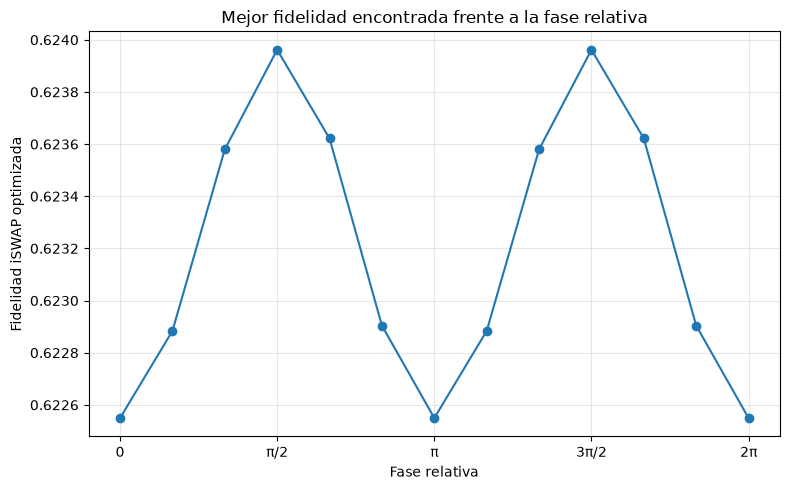

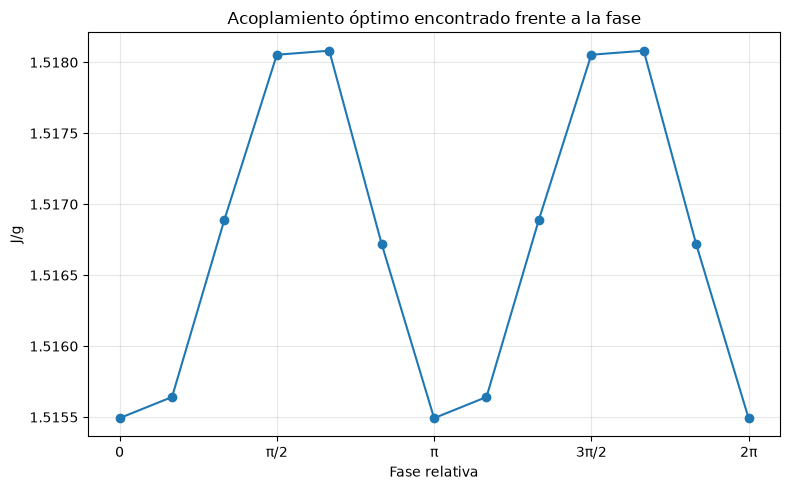

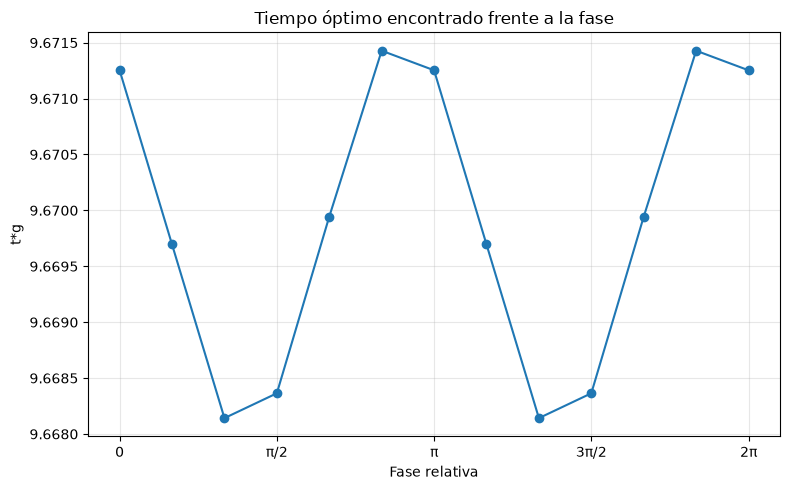

In [58]:
# Resumen numérico sin pandas

print("\nRESUMEN: MEJOR SOLUCIÓN ENCONTRADA PARA CADA FASE")
print("-" * 85)
print(
    f"{'Fase (rad)':>12} {'J/g':>12} {'tg':>12} "
    f"{'Fidelidad':>16} {'Pureza':>12} {'Entropía':>12}"
)

for r in best_phase_results:
    print(
        f"{r['delta']:12.4f} "
        f"{r['J_over_g']:12.6f} "
        f"{r['tg']:12.6f} "
        f"{r['fidelity']:16.8f} "
        f"{r['purity']:12.8f} "
        f"{r['entropy']:12.8f}"
    )


# Datos para las gráficas
phase_axis = np.array([r["delta"] for r in best_phase_results])
fidelity_axis = np.array([r["fidelity"] for r in best_phase_results])
coupling_axis = np.array([r["J_over_g"] for r in best_phase_results])
time_axis = np.array([r["tg"] for r in best_phase_results])

phase_ticks = [
    0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi
]
phase_tick_labels = [
    "0", "π/2", "π", "3π/2", "2π"
]


# Gráfica 1: fidelidad optimizada frente a fase
plt.figure(figsize=(8, 5))
plt.plot(phase_axis, fidelity_axis, marker="o")
plt.xticks(phase_ticks, phase_tick_labels)
plt.xlabel("Fase relativa")
plt.ylabel("Fidelidad iSWAP optimizada")
plt.title("Mejor fidelidad encontrada frente a la fase relativa")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfica 2: acoplamiento encontrado frente a fase
plt.figure(figsize=(8, 5))
plt.plot(phase_axis, coupling_axis, marker="o")
plt.xticks(phase_ticks, phase_tick_labels)
plt.xlabel("Fase relativa")
plt.ylabel("J/g")
plt.title("Acoplamiento óptimo encontrado frente a la fase")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfica 3: tiempo encontrado frente a fase
plt.figure(figsize=(8, 5))
plt.plot(phase_axis, time_axis, marker="o")
plt.xticks(phase_ticks, phase_tick_labels)
plt.xlabel("Fase relativa")
plt.ylabel("t*g")
plt.title("Tiempo óptimo encontrado frente a la fase")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [59]:
# Validación adicional de la región de mayor fidelidad
# Se conservan los mismos límites de la optimización previa.

additional_starts = [
    ("Inicio A", [0.3, 1.0]),
    ("Inicio B", [1.5, 1.0]),
    ("Inicio C", [1.8, 3.0]),
    ("Inicio D", [0.7, 4.0]),
]

additional_results = []

for delta, phase_label in [
    (0.0, "delta = 0"),
    (np.pi / 2, "delta = pi/2")
]:

    print("\n" + "=" * 70)
    print(f"VALIDACIÓN ADICIONAL: {phase_label}")
    print("=" * 70)

    for start_label, x0 in additional_starts:

        opt = minimize(
            objective_phase,
            x0=np.array(x0, dtype=float),
            args=(delta,),
            method="Powell",
            bounds=[
                (0.05, 2.0),
                (0.1, 12.0)
            ],
            options={
                "maxiter": 60,
                "xtol": 1e-3,
                "ftol": 1e-5,
                "disp": False
            }
        )

        J_found = float(opt.x[0])
        tg_found = float(opt.x[1])

        metrics = evaluate_phase(
            J_over_g=J_found,
            tg=tg_found,
            delta=delta
        )

        row = {
            "delta": delta,
            "phase": phase_label,
            "start": start_label,
            "J_over_g": J_found,
            "tg": tg_found,
            "fidelity": float(metrics["F_iSWAP"]),
            "purity": float(metrics["avg_purity"]),
            "entropy": float(metrics["avg_entropy"]),
            "success": bool(opt.success),
            "nfev": int(opt.nfev)
        }

        additional_results.append(row)

        print(
            f"{start_label}: "
            f"J/g={J_found:.8f}, "
            f"tg={tg_found:.8f}, "
            f"F={row['fidelity']:.8f}, "
            f"convergencia={row['success']}, "
            f"evaluaciones={row['nfev']}"
        )

print("\nValidación adicional terminada.")


VALIDACIÓN ADICIONAL: delta = 0
Inicio A: J/g=0.49981080, tg=5.69061670, F=0.60731666, convergencia=True, evaluaciones=123
Inicio B: J/g=0.49991765, tg=5.69101782, F=0.60731673, convergencia=True, evaluaciones=132
Inicio C: J/g=0.49971553, tg=5.68996404, F=0.60731634, convergencia=True, evaluaciones=211
Inicio D: J/g=1.51536200, tg=9.67203118, F=0.62254950, convergencia=True, evaluaciones=154

VALIDACIÓN ADICIONAL: delta = pi/2
Inicio A: J/g=0.50715431, tg=5.69060392, F=0.61304252, convergencia=True, evaluaciones=100
Inicio B: J/g=0.50712683, tg=5.69008540, F=0.61304255, convergencia=True, evaluaciones=107
Inicio C: J/g=0.50717805, tg=5.69076516, F=0.61304247, convergencia=True, evaluaciones=191
Inicio D: J/g=1.51817941, tg=9.66788987, F=0.62396192, convergencia=True, evaluaciones=146

Validación adicional terminada.


## Análisis de la fidelidad optimizada en función de la fase relativa

Se estudió la dependencia de la fidelidad iSWAP con la fase relativa entre los modos coherentes mediante un barrido de trece valores distribuidos entre \(0\) y \(2\pi\). Para cada fase se optimizaron los parámetros \(J/g\) y \(tg\) a partir de dos puntos iniciales, asociados a las regiones de convergencia identificadas previamente.

La preparación del campo se definió como

\[
\alpha=0.5,\qquad \beta=0.5e^{i\varphi},
\]

por lo que la ocupación media total del campo permaneció constante:

\[
\langle n_++n_-\rangle=0.5.
\]

### 1. Dependencia de la fidelidad con la fase relativa

La mayor fidelidad encontrada en el barrido fue

\[
F_{\mathrm{iSWAP}}=0.62396188,
\]

correspondiente a \(\varphi=\pi/2\) y \(3\pi/2\). Para estas fases, el optimizador encontró parámetros cercanos a \(J/g=1.518\) y \(tg=9.668\).

En contraste, para \(\varphi=0\), \(\pi\) y \(2\pi\), la fidelidad encontrada fue \(0.62254941\), con parámetros próximos a \(J/g=1.5155\) y \(tg=9.6713\).

La diferencia entre los valores máximo y mínimo encontrados es aproximadamente \(0.00141247\), lo que representa una variación relativa cercana al \(0.23\,\%\) respecto al mínimo observado. Por tanto, la fase relativa produce una modificación medible de la fidelidad optimizada, aunque la amplitud de esta variación es pequeña para las condiciones estudiadas.

### 2. Comportamiento de los parámetros optimizados

Los valores óptimos de \(J/g\) se encuentran aproximadamente entre \(1.515\) y \(1.518\), mientras que los de \(tg\) se sitúan alrededor de \(9.668\)–\(9.671\) en la región de mayor fidelidad.

Esta proximidad indica que los parámetros dinámicos encontrados varían moderadamente con la fase relativa en dicha región. Sin embargo, estos resultados corresponden a soluciones locales encontradas por el procedimiento numérico utilizado y no garantizan la existencia de un máximo global.

### 3. Simetría observada en la fase relativa

Las fidelidades obtenidas presentan una repetición al sumar \(\pi\) a la fase relativa. Por ejemplo, los resultados para \(\varphi=0\) y \(\pi\) coinciden numéricamente, al igual que los correspondientes a \(\pi/2\) y \(3\pi/2\).

Esta simetría también se observa en los valores de los parámetros optimizados y en las métricas de pureza y entropía reportadas. La repetición sugiere que, bajo las condiciones de simulación empleadas, las cantidades calculadas son invariantes frente a este cambio de fase.

No obstante, esta observación numérica no demuestra por sí sola una simetría universal para cualquier estado inicial, Hamiltoniano o conjunto de parámetros.

### 4. Relación con la pureza y la entropía

La fidelidad no presenta una relación monótona con la pureza promedio o la entropía promedio. Por ejemplo, las fases que producen las mayores fidelidades no son necesariamente aquellas que generan los estados reducidos más puros o con menor entropía.

Esto es consistente con el hecho de que las tres magnitudes caracterizan propiedades diferentes: la fidelidad cuantifica la proximidad del canal implementado a la operación iSWAP, mientras que la pureza y la entropía describen los estados reducidos de los qubits para las entradas de prueba consideradas.

### 5. Conclusión preliminar

En el dominio explorado, las mayores fidelidades se encontraron para las fases relativas próximas a \(\pi/2\) y \(3\pi/2\), con valores cercanos a \(0.624\). La variación con la fase es pequeña en comparación con la fidelidad total, pero permite identificar una dependencia sistemática de la operación optimizada respecto a la preparación inicial del campo.

Para determinar con mayor precisión la ubicación del máximo, el siguiente paso consiste en refinar el muestreo alrededor de \(\pi/2\) y optimizar los parámetros dinámicos con tolerancias numéricas más estrictas. Los resultados actuales deben interpretarse como los mejores valores encontrados en el barrido y no como una demostración de optimalidad global.


Fase = 1.047198 rad (60.00 grados)
  Rama corta: F=0.61244596, J/g=0.4938234, tg=5.6824665, convergencia=True
  Rama de mayor fidelidad: F=0.62357971, J/g=1.5169666, tg=9.6678427, convergencia=True
  Mejor F encontrada: 0.62357971

Fase = 1.178097 rad (67.50 grados)
  Rama corta: F=0.61281282, J/g=0.4965764, tg=5.6837941, convergencia=True
  Rama de mayor fidelidad: F=0.62373080, J/g=1.5173361, tg=9.6676252, convergencia=True
  Mejor F encontrada: 0.62373080

Fase = 1.308997 rad (75.00 grados)
  Rama corta: F=0.61303322, J/g=0.4997611, tg=5.6855472, convergencia=True
  Rama de mayor fidelidad: F=0.62385029, J/g=1.5176751, tg=9.6675602, convergencia=True
  Mejor F encontrada: 0.62385029

Fase = 1.439897 rad (82.50 grados)
  Rama corta: F=0.61310792, J/g=0.5032939, tg=5.6877182, convergencia=True
  Rama de mayor fidelidad: F=0.62392939, J/g=1.5179626, tg=9.6676505, convergencia=True
  Mejor F encontrada: 0.62392939

Fase = 1.570796 rad (90.00 grados)
  Rama corta: F=0.61304256, J/g=0.50

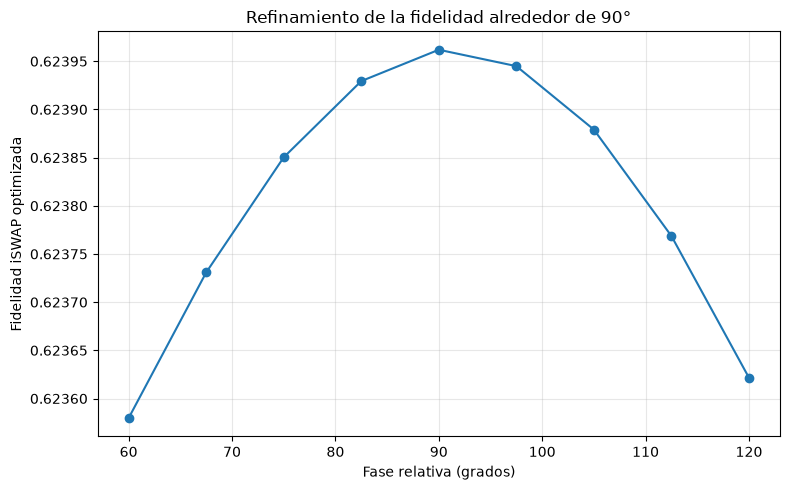


MEJOR RESULTADO DEL REFINAMIENTO
Fase:       1.57079633 rad
Fase:       90.00 grados
Fidelidad:  0.62396192
J/g:        1.51817962
tg:         9.66789018
Pureza:     0.54411099
Entropía:   1.18340824 bits


In [60]:
# Refinamiento del barrido de fase alrededor de pi/2
# Se reutilizan objective_phase() y evaluate_phase().

import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

fine_phases = np.linspace(np.pi/3, 2*np.pi/3, 9)

fine_starts = [
    ("Rama corta", [0.5, 5.69]),
    ("Rama de mayor fidelidad", [1.52, 9.67])
]

fine_bounds = [
    (0.05, 2.0),
    (0.1, 12.0)
]

fine_all_results = []
fine_best_results = []

for phi in fine_phases:
    candidates = []

    print(f"\nFase = {phi:.6f} rad ({np.degrees(phi):.2f} grados)")

    for branch, x0 in fine_starts:
        opt = minimize(
            objective_phase,
            x0=np.array(x0, dtype=float),
            args=(phi,),
            method="Powell",
            bounds=fine_bounds,
            options={
                "maxiter": 100,
                "xtol": 1e-4,
                "ftol": 1e-7,
                "disp": False
            }
        )

        J_value = float(opt.x[0])
        tg_value = float(opt.x[1])

        metrics = evaluate_phase(
            J_over_g=J_value,
            tg=tg_value,
            delta=phi
        )

        result = {
            "phi": float(phi),
            "degrees": float(np.degrees(phi)),
            "branch": branch,
            "J_over_g": J_value,
            "tg": tg_value,
            "fidelity": float(metrics["F_iSWAP"]),
            "purity": float(metrics["avg_purity"]),
            "entropy": float(metrics["avg_entropy"]),
            "success": bool(opt.success),
            "nfev": int(opt.nfev)
        }

        fine_all_results.append(result)
        candidates.append(result)

        print(
            f"  {branch}: F={result['fidelity']:.8f}, "
            f"J/g={J_value:.7f}, tg={tg_value:.7f}, "
            f"convergencia={opt.success}"
        )

    converged = [r for r in candidates if r["success"]]
    pool = converged if converged else candidates
    best = max(pool, key=lambda r: r["fidelity"])
    fine_best_results.append(best)

    print(f"  Mejor F encontrada: {best['fidelity']:.8f}")


# Gráfica del refinamiento
plt.figure(figsize=(8, 5))
plt.plot(
    [r["degrees"] for r in fine_best_results],
    [r["fidelity"] for r in fine_best_results],
    marker="o"
)
plt.xlabel("Fase relativa (grados)")
plt.ylabel("Fidelidad iSWAP optimizada")
plt.title("Refinamiento de la fidelidad alrededor de 90°")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Mejor fase del refinamiento
best_fine = max(fine_best_results, key=lambda r: r["fidelity"])

print("\nMEJOR RESULTADO DEL REFINAMIENTO")
print(f"Fase:       {best_fine['phi']:.8f} rad")
print(f"Fase:       {best_fine['degrees']:.2f} grados")
print(f"Fidelidad:  {best_fine['fidelity']:.8f}")
print(f"J/g:        {best_fine['J_over_g']:.8f}")
print(f"tg:         {best_fine['tg']:.8f}")
print(f"Pureza:     {best_fine['purity']:.8f}")
print(f"Entropía:   {best_fine['entropy']:.8f} bits")

## Refinamiento de la fase relativa en la región de mayor fidelidad

Con el propósito de localizar con mayor precisión la fase relativa que favorece la implementación de la compuerta iSWAP, se realizó un segundo barrido en el intervalo

\[
\frac{\pi}{3}\leq\varphi\leq\frac{2\pi}{3},
\]

correspondiente a fases entre \(60^\circ\) y \(120^\circ\). Para cada fase se optimizaron el cociente de acoplamiento \(J/g\) y el tiempo adimensional \(tg\), considerando las dos regiones de convergencia encontradas anteriormente.

### 1. Identificación del máximo en la malla evaluada

La mayor fidelidad obtenida en este refinamiento fue

\[
F_{\mathrm{iSWAP}}=0.62396192,
\]

para

\[
\varphi=\frac{\pi}{2}=90^\circ,
\]

con los parámetros

\[
\frac{J}{g}=1.51817962,\qquad tg=9.66789018.
\]

La fidelidad aumenta desde \(0.62357971\) a \(60^\circ\) hasta \(0.62396192\) a \(90^\circ\), y después disminuye hasta \(0.62362157\) a \(120^\circ\).

La diferencia entre el máximo y el mínimo del intervalo estudiado es aproximadamente \(3.82\times10^{-4}\). Por lo tanto, la variación de la fidelidad alrededor de esta región es pequeña, aunque presenta un máximo identificable en los puntos examinados.

### 2. Comportamiento de los parámetros dinámicos

En la región de mayor fidelidad, el cociente de acoplamiento se mantiene próximo a \(J/g=1.518\), mientras que el tiempo adimensional permanece alrededor de \(tg=9.668\).

Esta estabilidad sugiere que los parámetros dinámicos óptimos encontrados varían poco con la fase relativa en el intervalo estudiado. Sin embargo, la cercanía de los resultados también hace necesario distinguir las variaciones físicas reales de las pequeñas diferencias asociadas con la tolerancia numérica de la optimización.

### 3. Alcance del refinamiento

El resultado de \(90^\circ\) corresponde al mayor valor encontrado entre los puntos discretos evaluados, no a una demostración de que la fase óptima exacta sea necesariamente \(\pi/2\).

Para investigar esta cuestión, en el siguiente paso se optimizarán simultáneamente las tres variables \(\varphi\), \(J/g\) y \(tg\). Este procedimiento permitirá refinar la ubicación del máximo sin limitar la fase a una malla previamente establecida.

La optimización conjunta seguirá siendo numérica y local, de modo que sus resultados deberán interpretarse como la mejor solución encontrada por el algoritmo y no como una prueba de optimalidad global.

In [61]:
# Optimización conjunta de:
# x[0] = J/g
# x[1] = t*g
# x[2] = fase relativa phi

import numpy as np
from scipy.optimize import minimize

Nf_joint = 10
g_joint = 1.0

def objective_joint(x):
    J_over_g, tg, phi = x

    result = evaluate_point(
        J=J_over_g * g_joint,
        t=tg / g_joint,
        alpha=0.5,
        beta=0.5 * np.exp(1j * phi),
        g=g_joint,
        Nf=Nf_joint
    )

    return -float(result["F_iSWAP"])


# Mejor solución encontrada en el barrido refinado
x0_joint = [
    1.51817962,
    9.66789018,
    np.pi / 2
]

# Límites de búsqueda
bounds_joint = [
    (0.05, 2.0),       # J/g
    (0.1, 12.0),       # t*g
    (0.0, 2*np.pi)     # fase relativa
]

# Fidelidad en el punto inicial
F_initial_joint = -objective_joint(x0_joint)

# Optimización conjunta
opt_joint = minimize(
    objective_joint,
    x0=np.array(x0_joint, dtype=float),
    method="Powell",
    bounds=bounds_joint,
    options={
        "maxiter": 100,
        "xtol": 1e-5,
        "ftol": 1e-8,
        "disp": False
    }
)

J_joint, tg_joint, phi_joint = opt_joint.x

# Recalcular todas las métricas en la solución final
metrics_joint = evaluate_point(
    J=J_joint * g_joint,
    t=tg_joint / g_joint,
    alpha=0.5,
    beta=0.5 * np.exp(1j * phi_joint),
    g=g_joint,
    Nf=Nf_joint
)

print("=" * 65)
print("OPTIMIZACIÓN CONJUNTA DE FASE, ACOPLAMIENTO Y TIEMPO")
print("=" * 65)

print(f"Fidelidad inicial:      {F_initial_joint:.10f}")
print(f"Fidelidad final:        {metrics_joint['F_iSWAP']:.10f}")
print(f"J/g encontrado:         {J_joint:.10f}")
print(f"t*g encontrado:         {tg_joint:.10f}")
print(f"Fase encontrada (rad):  {phi_joint:.10f}")
print(f"Fase encontrada (°):    {np.degrees(phi_joint):.6f}")
print(f"Pureza promedio:        {metrics_joint['avg_purity']:.10f}")
print(f"Entropía promedio:      {metrics_joint['avg_entropy']:.10f} bits")
print(f"Convergencia:           {opt_joint.success}")
print(f"Evaluaciones:           {opt_joint.nfev}")
print(f"Mensaje: {opt_joint.message}")

OPTIMIZACIÓN CONJUNTA DE FASE, ACOPLAMIENTO Y TIEMPO
Fidelidad inicial:      0.6239619233
Fidelidad final:        0.6239625592
J/g encontrado:         1.5182125315
t*g encontrado:         9.6679225349
Fase encontrada (rad):  1.5917001406
Fase encontrada (°):    91.197700
Pureza promedio:        0.5440059223
Entropía promedio:      1.1837134854 bits
Convergencia:           True
Evaluaciones:           158
Mensaje: Optimization terminated successfully.


## Optimización conjunta de la fase relativa y los parámetros dinámicos

A partir del refinamiento de la fase relativa, se realizó una optimización conjunta de las variables

\[
\left(\frac{J}{g},tg,\varphi\right),
\]

con el objetivo de maximizar la fidelidad iSWAP. La búsqueda se inició desde la solución de mayor fidelidad identificada en el barrido anterior.

Este procedimiento permite que la fase relativa cambie simultáneamente con el acoplamiento y el tiempo de evolución, a diferencia de las optimizaciones previas, en las que la fase se mantenía fija.

Los resultados obtenidos se compararán con el máximo encontrado en el barrido discreto:

\[
F_{\mathrm{iSWAP}}=0.62396192,
\qquad
\varphi=\frac{\pi}{2}.
\]

Si la optimización conjunta produce una fidelidad superior, se registrarán los nuevos parámetros y la fase correspondiente como la mejor solución encontrada por este procedimiento. Si la fidelidad permanece prácticamente igual y la fase continúa cerca de \(\pi/2\), ello aportará evidencia adicional de la estabilidad de la solución.

En ambos casos, el resultado se interpretará como un máximo numérico local. Para sostener una afirmación de optimalidad global sería necesario realizar una búsqueda más amplia y comprobar que no existen otras regiones con fidelidades superiores.

## Resultados de la optimización conjunta de la fase relativa y los parámetros dinámicos

Se realizó una optimización numérica simultánea de la fase relativa \(\varphi\), el cociente de acoplamiento \(J/g\) y el tiempo adimensional \(tg\), manteniendo la preparación inicial del campo en la forma

\[
\alpha=0.5,\qquad \beta=0.5e^{i\varphi}.
\]

La optimización se inició desde la mejor solución identificada en el barrido de fase anterior. El algoritmo terminó satisfactoriamente y encontró los siguientes parámetros:

\[
\frac{J}{g}=1.5182125315,
\]

\[
tg=9.6679225349,
\]

\[
\varphi=1.5917001406\ \text{rad}
\approx91.1977^\circ.
\]

La fidelidad obtenida fue

\[
F_{\mathrm{iSWAP}}=0.6239625592.
\]

Este valor supera ligeramente la fidelidad de \(0.6239619233\) encontrada en el barrido discreto para \(\varphi=\pi/2\). La diferencia absoluta es

\[
\Delta F=6.359\times10^{-7}.
\]

Aunque el algoritmo reportó convergencia satisfactoria, la magnitud tan pequeña de la mejora impide atribuir significado físico a la diferencia entre \(90^\circ\) y \(91.1977^\circ\) sin pruebas adicionales de estabilidad numérica.

La pureza promedio obtenida fue \(0.5440059223\), mientras que la entropía promedio alcanzó \(1.1837134854\) bits. Estas cantidades describen los estados reducidos de los qubits para las entradas consideradas y no constituyen por sí solas un criterio de optimalidad de la compuerta.

En consecuencia, el resultado debe interpretarse como la mejor solución encontrada por esta ejecución de la optimización conjunta. El siguiente paso consiste en repetir la búsqueda desde distintos puntos iniciales y verificar si se obtiene una solución consistente dentro de la precisión numérica de la simulación.

In [62]:
# Validación de la optimización conjunta con varios puntos iniciales
# Requiere que objective_joint() esté definida previamente.

import numpy as np
from scipy.optimize import minimize

joint_starts = [
    ("Solución conjunta anterior",
     [1.51821253, 9.66792253, 1.59170014]),

    ("Inicio en 90 grados",
     [1.51817962, 9.66789018, np.pi / 2]),

    ("Inicio alternativo A",
     [1.50, 9.70, 1.40]),

    ("Inicio alternativo B",
     [1.60, 9.60, 1.80])
]

joint_bounds = [
    (0.05, 2.0),       # J/g
    (0.1, 12.0),       # t*g
    (0.0, 2*np.pi)     # fase relativa
]

joint_validation_results = []

for label, x0 in joint_starts:

    opt = minimize(
        objective_joint,
        x0=np.array(x0, dtype=float),
        method="Powell",
        bounds=joint_bounds,
        options={
            "maxiter": 150,
            "xtol": 1e-6,
            "ftol": 1e-9,
            "disp": False
        }
    )

    J_found, tg_found, phi_found = opt.x

    metrics = evaluate_point(
        J=float(J_found),
        t=float(tg_found),
        alpha=0.5,
        beta=0.5 * np.exp(1j * float(phi_found)),
        g=1.0,
        Nf=10
    )

    row = {
        "label": label,
        "J_over_g": float(J_found),
        "tg": float(tg_found),
        "phi": float(phi_found),
        "fidelity": float(metrics["F_iSWAP"]),
        "purity": float(metrics["avg_purity"]),
        "entropy": float(metrics["avg_entropy"]),
        "success": bool(opt.success),
        "nfev": int(opt.nfev)
    }

    joint_validation_results.append(row)

    print("\n" + "-" * 65)
    print(label)
    print(f"J/g:             {row['J_over_g']:.10f}")
    print(f"t*g:             {row['tg']:.10f}")
    print(f"Fase (rad):      {row['phi']:.10f}")
    print(f"Fase (grados):   {np.degrees(row['phi']):.6f}")
    print(f"Fidelidad:       {row['fidelity']:.10f}")
    print(f"Pureza promedio: {row['purity']:.10f}")
    print(f"Entropía (bits): {row['entropy']:.10f}")
    print(f"Convergencia:    {row['success']}")
    print(f"Evaluaciones:    {row['nfev']}")

# Mejor resultado entre las ejecuciones que reportaron convergencia
converged_results = [
    r for r in joint_validation_results if r["success"]
]

if converged_results:
    best_joint = max(
        converged_results,
        key=lambda r: r["fidelity"]
    )

    print("\n" + "=" * 65)
    print("MEJOR SOLUCIÓN DE LA VALIDACIÓN")
    print("=" * 65)
    print(f"Fidelidad:     {best_joint['fidelity']:.10f}")
    print(f"J/g:           {best_joint['J_over_g']:.10f}")
    print(f"t*g:           {best_joint['tg']:.10f}")
    print(f"Fase (rad):    {best_joint['phi']:.10f}")
    print(f"Fase (grados): {np.degrees(best_joint['phi']):.6f}")
else:
    print("Ninguna ejecución reportó convergencia satisfactoria.")


-----------------------------------------------------------------
Solución conjunta anterior
J/g:             1.5182096865
t*g:             9.6679304942
Fase (rad):      1.5916924994
Fase (grados):   91.197262
Fidelidad:       0.6239625592
Pureza promedio: 0.5440064070
Entropía (bits): 1.1837121662
Convergencia:    True
Evaluaciones:    36

-----------------------------------------------------------------
Inicio en 90 grados
J/g:             1.5182114738
t*g:             9.6679248166
Fase (rad):      1.5916967395
Fase (grados):   91.197505
Fidelidad:       0.6239625592
Pureza promedio: 0.5440060381
Entropía (bits): 1.1837130790
Convergencia:    True
Evaluaciones:    109

-----------------------------------------------------------------
Inicio alternativo A
J/g:             1.5182064390
t*g:             9.6679423893
Fase (rad):      1.5916362387
Fase (grados):   91.194039
Fidelidad:       0.6239625593
Pureza promedio: 0.5440074941
Entropía (bits): 1.1837095876
Convergencia:    True
Eva

## Validación de la estabilidad de la optimización conjunta

Para evaluar la sensibilidad de la solución respecto al punto inicial, se repitió la optimización conjunta de la fase relativa \(\varphi\), el cociente de acoplamiento \(J/g\) y el tiempo adimensional \(tg\), empleando cuatro puntos iniciales diferentes.

Las cuatro ejecuciones reportaron convergencia satisfactoria. Las fidelidades obtenidas se situaron entre \(0.6239625592\) y \(0.6239625593\), mientras que los parámetros encontrados permanecieron próximos a

\[
\frac{J}{g}\approx1.51821,\qquad
tg\approx9.66793,\qquad
\varphi\approx1.59169\ \text{rad}.
\]

La solución con mayor fidelidad reportada fue

\[
F_{\mathrm{iSWAP}}=0.6239625593,
\]

con

\[
\frac{J}{g}=1.5182065768,\qquad
tg=9.6679403313,
\]

y una fase relativa aproximada de \(91.1968^\circ\).

La coincidencia de las fidelidades y la proximidad de los parámetros obtenidos desde distintos puntos de partida aportan evidencia de que la solución es estable respecto a la inicialización del optimizador, dentro de la precisión numérica empleada.

No obstante, esta comprobación no demuestra la optimalidad global. Además, todas las ejecuciones se realizaron con truncamiento \(N_f=10\), por lo que todavía es necesario evaluar la convergencia respecto al tamaño de la base de Fock.

### Conclusión

La optimización conjunta presenta una solución numéricamente reproducible, con una fidelidad de aproximadamente \(0.623963\). Antes de considerar definitivo este resultado, se estudiará si las métricas calculadas permanecen estables al aumentar la dimensión de los dos modos del campo.

In [63]:
# Prueba de convergencia respecto al truncamiento de Fock
# Se mantienen fijos los parámetros de la mejor solución encontrada.

import numpy as np
import matplotlib.pyplot as plt

J_conv = 1.5182065768
tg_conv = 9.6679403313
phi_conv = 1.5916841115
g_conv = 1.0

alpha_conv = 0.5
beta_conv = 0.5 * np.exp(1j * phi_conv)

# Dimensión de cada modo del campo
Nf_values = [3, 4, 6, 8, 10]

truncation_results = []

print("=" * 85)
print("CONVERGENCIA RESPECTO AL TRUNCAMIENTO DE FOCK")
print("=" * 85)

for Nf in Nf_values:

    result = evaluate_point(
        J=J_conv,
        t=tg_conv / g_conv,
        alpha=alpha_conv,
        beta=beta_conv,
        g=g_conv,
        Nf=Nf
    )

    row = {
        "Nf": Nf,
        "fidelity": float(result["F_iSWAP"]),
        "purity": float(result["avg_purity"]),
        "entropy": float(result["avg_entropy"])
    }

    truncation_results.append(row)

    print(
        f"Nf={Nf:2d} | "
        f"F={row['fidelity']:.10f} | "
        f"Pureza={row['purity']:.10f} | "
        f"Entropía={row['entropy']:.10f} bits"
    )

# Comparación con Nf=10
reference = next(
    r for r in truncation_results if r["Nf"] == 10
)

print("\nDIFERENCIAS ABSOLUTAS RESPECTO A Nf=10")
print("-" * 85)

for r in truncation_results:
    print(
        f"Nf={r['Nf']:2d} | "
        f"|ΔF|={abs(r['fidelity'] - reference['fidelity']):.3e} | "
        f"|ΔP|={abs(r['purity'] - reference['purity']):.3e} | "
        f"|ΔS|={abs(r['entropy'] - reference['entropy']):.3e}"
    )

CONVERGENCIA RESPECTO AL TRUNCAMIENTO DE FOCK
Nf= 3 | F=0.6482867192 | Pureza=0.6145158274 | Entropía=0.9969860485 bits
Nf= 4 | F=0.6184637995 | Pureza=0.5367725600 | Entropía=1.2033963735 bits
Nf= 6 | F=0.6239493238 | Pureza=0.5440289162 | Entropía=1.1836651306 bits
Nf= 8 | F=0.6239625859 | Pureza=0.5440067044 | Entropía=1.1837117887 bits
Nf=10 | F=0.6239625593 | Pureza=0.5440070501 | Entropía=1.1837105690 bits

DIFERENCIAS ABSOLUTAS RESPECTO A Nf=10
-------------------------------------------------------------------------------------
Nf= 3 | |ΔF|=2.432e-02 | |ΔP|=7.051e-02 | |ΔS|=1.867e-01
Nf= 4 | |ΔF|=5.499e-03 | |ΔP|=7.234e-03 | |ΔS|=1.969e-02
Nf= 6 | |ΔF|=1.324e-05 | |ΔP|=2.187e-05 | |ΔS|=4.544e-05
Nf= 8 | |ΔF|=2.659e-08 | |ΔP|=3.456e-07 | |ΔS|=1.220e-06
Nf=10 | |ΔF|=0.000e+00 | |ΔP|=0.000e+00 | |ΔS|=0.000e+00



CONVERGENCIA RESPECTO AL TRUNCAMIENTO DE FOCK
=====================================================================================
Nf= 3 | F=0.6482867192 | Pureza=0.6145158274 | Entropía=0.9969860485 bits
Nf= 4 | F=0.6184637995 | Pureza=0.5367725600 | Entropía=1.2033963735 bits
Nf= 6 | F=0.6239493238 | Pureza=0.5440289162 | Entropía=1.1836651306 bits
Nf= 8 | F=0.6239625859 | Pureza=0.5440067044 | Entropía=1.1837117887 bits
Nf=10 | F=0.6239625593 | Pureza=0.5440070501 | Entropía=1.1837105690 bits

DIFERENCIAS ABSOLUTAS RESPECTO A Nf=10
-------------------------------------------------------------------------------------
Nf= 3 | |ΔF|=2.432e-02 | |ΔP|=7.051e-02 | |ΔS|=1.867e-01
Nf= 4 | |ΔF|=5.499e-03 | |ΔP|=7.234e-03 | |ΔS|=1.969e-02
Nf= 6 | |ΔF|=1.324e-05 | |ΔP|=2.187e-05 | |ΔS|=4.544e-05
Nf= 8 | |ΔF|=2.659e-08 | |ΔP|=3.456e-07 | |ΔS|=1.220e-06
Nf=10 | |ΔF|=0.000e+00 | |ΔP|=0.000e+00 | |ΔS|=0.000e+00

In [64]:
# Verificación final con Nf = 12
# Se mantienen fijos los parámetros de la solución validada.

result_Nf12 = evaluate_point(
    J=1.5182065768,
    t=9.6679403313,
    alpha=0.5,
    beta=0.5 * np.exp(1j * 1.5916841115),
    g=1.0,
    Nf=12
)

print("RESULTADOS CON Nf = 12")
print(f"Fidelidad iSWAP:  {result_Nf12['F_iSWAP']:.10f}")
print(f"Pureza promedio:  {result_Nf12['avg_purity']:.10f}")
print(f"Entropía promedio:{result_Nf12['avg_entropy']:.10f} bits")

print("\nDiferencias absolutas respecto a Nf = 10")
print(
    f"|ΔF| = "
    f"{abs(result_Nf12['F_iSWAP'] - 0.6239625593):.3e}"
)
print(
    f"|ΔP| = "
    f"{abs(result_Nf12['avg_purity'] - 0.5440070501):.3e}"
)
print(
    f"|ΔS| = "
    f"{abs(result_Nf12['avg_entropy'] - 1.1837105690):.3e} bits"
)

RESULTADOS CON Nf = 12
Fidelidad iSWAP:  0.6239625593
Pureza promedio:  0.5440070495
Entropía promedio:1.1837105685 bits

Diferencias absolutas respecto a Nf = 10
|ΔF| = 1.656e-11
|ΔP| = 6.074e-10
|ΔS| = 4.753e-10 bits


## Verificación final de la convergencia de la base de Fock

Como comprobación adicional de la convergencia numérica, se evaluó la dinámica con \(N_f=12\), manteniendo fijos los parámetros correspondientes a la mejor solución encontrada mediante la optimización conjunta:

\[
\frac{J}{g}=1.5182065768,\qquad
tg=9.6679403313,\qquad
\varphi=1.5916841115\ \text{rad}.
\]

La comparación entre \(N_f=10\) y \(N_f=12\) produjo los siguientes resultados:

| Magnitud | \(N_f=10\) | \(N_f=12\) | Diferencia absoluta |
|:--|--:|--:|--:|
| Fidelidad iSWAP | 0.6239625593 | 0.6239625593 | \(1.656\times10^{-11}\) |
| Pureza promedio | 0.5440070501 | 0.5440070495 | \(6.074\times10^{-10}\) |
| Entropía promedio (bits) | 1.1837105690 | 1.1837105685 | \(4.753\times10^{-10}\) |

Las diferencias entre ambas dimensiones son extremadamente pequeñas. Por consiguiente, los resultados muestran convergencia respecto al truncamiento para el estado coherente y los parámetros dinámicos considerados.

En consecuencia, se utilizará \(N_f=10\) como dimensión de referencia para continuar las simulaciones, ya que reproduce los resultados obtenidos con \(N_f=12\) con una precisión ampliamente suficiente para el análisis actual. Esta conclusión se refiere a la configuración estudiada y deberá revisarse si se modifican sustancialmente las amplitudes coherentes.



## Influencia de la amplitud coherente sobre la fidelidad optimizada

Una vez comprobada la convergencia respecto a la dimensión de la base de Fock, se estudia la influencia de la amplitud coherente inicial sobre la implementación de la compuerta iSWAP.

Se considera la familia de estados del campo

\[
|\Psi_F(0)\rangle=|A\rangle_+\otimes|Ae^{i\varphi}\rangle_-,
\]

donde \(A\) es una amplitud real no negativa y la fase relativa se mantiene fija en el valor encontrado mediante la optimización conjunta:

\[
\varphi=1.5916841115\ \text{rad}.
\]

La ocupación media total de los dos modos es

\[
\langle n_++n_-\rangle=2A^2.
\]

Por tanto, variar \(A\) modifica la ocupación media inicial del campo y permite investigar cómo influye en la fidelidad de la compuerta.

Para cada amplitud se optimizarán \(J/g\) y \(tg\) desde dos puntos iniciales asociados a las regiones de convergencia identificadas previamente. Se seleccionará la mayor fidelidad entre las soluciones que reporten convergencia satisfactoria.

Este procedimiento permite comparar el campo vacío con distintas preparaciones coherentes, ajustando los parámetros dinámicos en cada caso. Sin embargo, la búsqueda seguirá siendo local y no garantizará que se haya encontrado el máximo global para cada amplitud.

Los resultados permitirán determinar si la fidelidad optimizada disminuye sistemáticamente al incrementar la ocupación media o si aparecen regiones en las que el ajuste de los parámetros dinámicos compensa parcialmente el efecto de la excitación del campo.


Amplitud A = 0.00
Ocupación media total = 0.0000
  Rama corta: F=0.86363328, J/g=0.504637, tg=5.691754, convergencia=True
  Rama de mayor fidelidad: F=0.87691852, J/g=1.513686, tg=9.646166, convergencia=True
  Mejor fidelidad encontrada: 0.87691852

Amplitud A = 0.10
Ocupación media total = 0.0200
  Rama corta: F=0.85059037, J/g=0.504436, tg=5.691338, convergencia=True
  Rama de mayor fidelidad: F=0.86380258, J/g=1.513878, tg=9.646115, convergencia=True
  Mejor fidelidad encontrada: 0.86380258

Amplitud A = 0.20
Ocupación media total = 0.0800
  Rama corta: F=0.81321882, J/g=0.504003, tg=5.690255, convergencia=True
  Rama de mayor fidelidad: F=0.82621782, J/g=1.514445, tg=9.646434, convergencia=True
  Mejor fidelidad encontrada: 0.82621782

Amplitud A = 0.30
Ocupación media total = 0.1800
  Rama corta: F=0.75640014, J/g=0.503830, tg=5.689054, convergencia=True
  Rama de mayor fidelidad: F=0.76903395, J/g=1.515363, tg=9.648577, convergencia=True
  Mejor fidelidad encontrada: 0.76903395


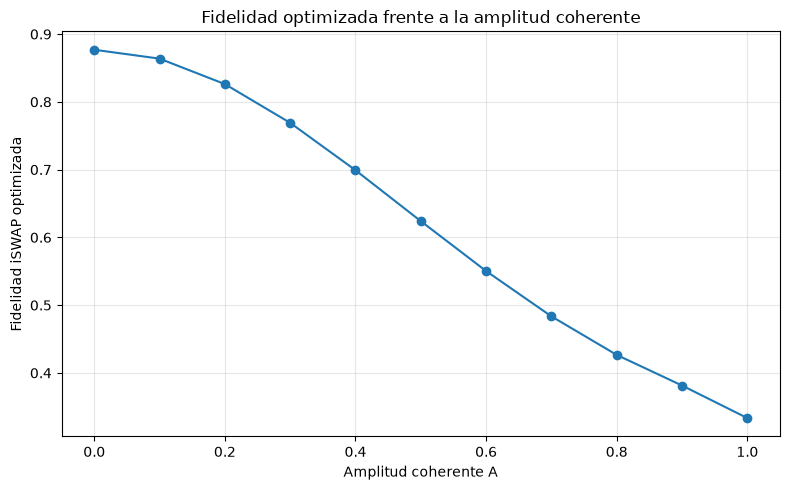

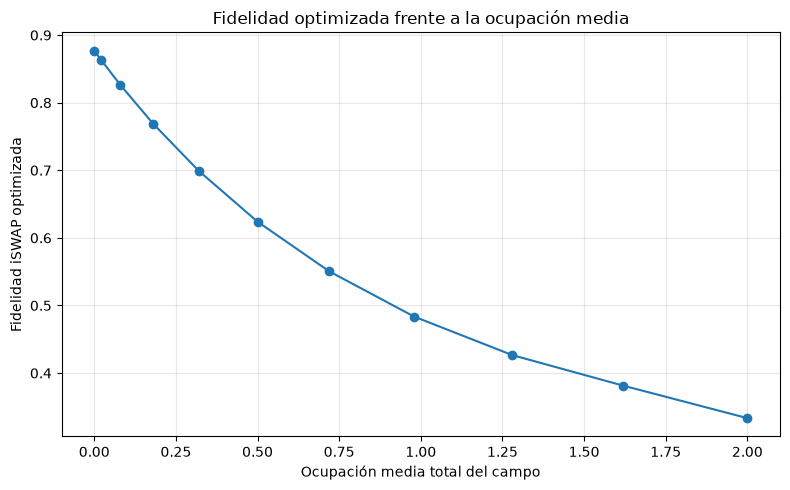


RESUMEN DE LA OPTIMIZACIÓN POR AMPLITUD
------------------------------------------------------------------------------------------
     A    <n_total>          J/g           tg      Fidelidad       Pureza     Entropía
  0.00       0.0000     1.513686     9.646166     0.87691852   0.78852898   0.56331001
  0.10       0.0200     1.513878     9.646115     0.86380258   0.77095932   0.61714321
  0.20       0.0800     1.514445     9.646434     0.82621782   0.72378335   0.73871396
  0.30       0.1800     1.515363     9.648577     0.76903395   0.66077025   0.89112399
  0.40       0.3200     1.516609     9.654785     0.69912422   0.59727015   1.04591196
  0.50       0.5000     1.518211     9.667928     0.62396256   0.54400631   1.18371250
  0.60       0.7200     1.520351     9.690210     0.55033803   0.50459537   1.29437450
  0.70       0.9800     1.523844     9.720540     0.48346086   0.47684076   1.37665396
  0.80       1.2800     1.531624     9.749867     0.42658694   0.45530805   1.4392792

In [65]:
# Influencia de la amplitud coherente sobre la fidelidad optimizada
# Fase relativa fija en el valor encontrado anteriormente.

import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

phi_fixed = 1.5916841115
Nf_amp = 10
g_amp = 1.0

amplitude_values = np.linspace(0.0, 1.0, 11)

amplitude_starts = [
    ("Rama corta", [0.5, 5.69]),
    ("Rama de mayor fidelidad", [1.5182, 9.6679])
]

amplitude_bounds = [
    (0.05, 2.0),   # J/g
    (0.1, 12.0)    # t*g
]

amplitude_results_all = []
amplitude_results_best = []


def objective_amplitude(x, A):
    """Negativo de la fidelidad para una amplitud coherente dada."""
    J_over_g, tg = x

    result = evaluate_point(
        J=J_over_g * g_amp,
        t=tg / g_amp,
        alpha=A,
        beta=A * np.exp(1j * phi_fixed),
        g=g_amp,
        Nf=Nf_amp
    )

    return -float(result["F_iSWAP"])


for A in amplitude_values:

    candidates = []

    print(f"\nAmplitud A = {A:.2f}")
    print(f"Ocupación media total = {2*A**2:.4f}")

    for branch, x0 in amplitude_starts:

        opt = minimize(
            objective_amplitude,
            x0=np.array(x0, dtype=float),
            args=(A,),
            method="Powell",
            bounds=amplitude_bounds,
            options={
                "maxiter": 100,
                "xtol": 1e-4,
                "ftol": 1e-7,
                "disp": False
            }
        )

        J_found = float(opt.x[0])
        tg_found = float(opt.x[1])

        metrics = evaluate_point(
            J=J_found * g_amp,
            t=tg_found / g_amp,
            alpha=A,
            beta=A * np.exp(1j * phi_fixed),
            g=g_amp,
            Nf=Nf_amp
        )

        row = {
            "A": float(A),
            "mean_photons": float(2*A**2),
            "branch": branch,
            "J_over_g": J_found,
            "tg": tg_found,
            "fidelity": float(metrics["F_iSWAP"]),
            "purity": float(metrics["avg_purity"]),
            "entropy": float(metrics["avg_entropy"]),
            "success": bool(opt.success),
            "nfev": int(opt.nfev)
        }

        amplitude_results_all.append(row)
        candidates.append(row)

        print(
            f"  {branch}: "
            f"F={row['fidelity']:.8f}, "
            f"J/g={J_found:.6f}, "
            f"tg={tg_found:.6f}, "
            f"convergencia={opt.success}"
        )

    converged = [r for r in candidates if r["success"]]
    pool = converged if converged else candidates

    best = max(pool, key=lambda r: r["fidelity"])
    amplitude_results_best.append(best)

    print(
        f"  Mejor fidelidad encontrada: {best['fidelity']:.8f}"
    )


# Gráfica 1: fidelidad optimizada respecto a A
plt.figure(figsize=(8, 5))
plt.plot(
    [r["A"] for r in amplitude_results_best],
    [r["fidelity"] for r in amplitude_results_best],
    marker="o"
)
plt.xlabel("Amplitud coherente A")
plt.ylabel("Fidelidad iSWAP optimizada")
plt.title("Fidelidad optimizada frente a la amplitud coherente")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfica 2: fidelidad respecto a la ocupación media
plt.figure(figsize=(8, 5))
plt.plot(
    [r["mean_photons"] for r in amplitude_results_best],
    [r["fidelity"] for r in amplitude_results_best],
    marker="o"
)
plt.xlabel("Ocupación media total del campo")
plt.ylabel("Fidelidad iSWAP optimizada")
plt.title("Fidelidad optimizada frente a la ocupación media")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Resumen numérico
print("\nRESUMEN DE LA OPTIMIZACIÓN POR AMPLITUD")
print("-" * 90)
print(
    f"{'A':>6} {'<n_total>':>12} {'J/g':>12} "
    f"{'tg':>12} {'Fidelidad':>14} "
    f"{'Pureza':>12} {'Entropía':>12}"
)

for r in amplitude_results_best:
    print(
        f"{r['A']:6.2f} "
        f"{r['mean_photons']:12.4f} "
        f"{r['J_over_g']:12.6f} "
        f"{r['tg']:12.6f} "
        f"{r['fidelity']:14.8f} "
        f"{r['purity']:12.8f} "
        f"{r['entropy']:12.8f}"
    )

## Influencia de la amplitud coherente sobre la fidelidad optimizada

Se estudió la influencia de la amplitud coherente inicial sobre la implementación de la compuerta iSWAP. Para ello, se consideraron estados iniciales de los modos normales de la forma

\[
|\Psi_F(0)\rangle=|A\rangle_+\otimes|Ae^{i\varphi}\rangle_-,
\]

con una fase relativa fija \(\varphi=1.5916841115\) rad. Para cada amplitud \(A\), se optimizaron numéricamente \(J/g\) y \(tg\) desde dos puntos iniciales, seleccionando la mayor fidelidad entre las soluciones que reportaron convergencia satisfactoria.

La ocupación media total del campo está dada por

\[
\langle n_++n_-\rangle=2A^2.
\]

### 1. Dependencia de la fidelidad con la amplitud

Para el campo inicialmente en el vacío, \(A=0\), la mayor fidelidad encontrada fue \(0.87691852\). Al aumentar la amplitud, la fidelidad disminuyó progresivamente: para \(A=0.5\) se obtuvo \(0.62396256\), y para \(A=1\) se obtuvo \(0.33333876\).

La tendencia se observa en toda la secuencia de amplitudes evaluadas:

| Amplitud \(A\) | Ocupación media total | Fidelidad optimizada encontrada |
|--:|--:|--:|
| 0.0 | 0.00 | 0.87691852 |
| 0.1 | 0.02 | 0.86380258 |
| 0.2 | 0.08 | 0.82621782 |
| 0.3 | 0.18 | 0.76903395 |
| 0.4 | 0.32 | 0.69912422 |
| 0.5 | 0.50 | 0.62396256 |
| 0.6 | 0.72 | 0.55033803 |
| 0.7 | 0.98 | 0.48346086 |
| 0.8 | 1.28 | 0.42658694 |
| 0.9 | 1.62 | 0.38137063 |
| 1.0 | 2.00 | 0.33333876 |

Estos resultados indican que, para la fase relativa y el procedimiento de optimización utilizados, el aumento de la ocupación media del campo está asociado con una disminución de la mejor fidelidad encontrada. Esta tendencia no demuestra que la fidelidad deba disminuir para toda preparación coherente, ya que no se han explorado todas las fases ni se ha demostrado la optimalidad global de cada solución.

### 2. Comportamiento de la pureza y la entropía promedio

La pureza promedio disminuyó de \(0.78852898\) para el vacío a \(0.40377173\) para \(A=1\). En cambio, la entropía promedio aumentó de \(0.56331001\) a \(1.59313244\) bits.

Este comportamiento es consistente con una mayor mezcla de los estados reducidos de los qubits conforme aumenta la amplitud coherente del campo. Para cada entrada pura de la base computacional, la entropía reducida de los qubits cuantifica su entrelazamiento con el campo en la evolución unitaria considerada.

Las cantidades reportadas son promedios sobre las cuatro entradas de la base computacional. Por ello, caracterizan el comportamiento de esas entradas de prueba y no constituyen por sí solas una medida completa de la capacidad de entrelazamiento del canal.

### 3. Evolución de los parámetros optimizados

En la rama que proporcionó la mayor fidelidad encontrada, el cociente \(J/g\) aumentó de aproximadamente \(1.5137\) para \(A=0\) a \(1.5524\) para \(A=0.9\). Para \(A=1\), el valor encontrado fue \(1.5923\).

El tiempo adimensional se mantuvo cerca de \(tg\approx9.65\)–\(9.75\) hasta \(A=0.9\), pero para \(A=1\) se encontró \(tg=7.5709\). Este cambio sugiere que la optimización pudo converger a una región diferente del espacio de parámetros en la última amplitud.

Por tanto, conviene verificar la estabilidad de ese resultado con puntos iniciales adicionales y comprobar la convergencia respecto a la dimensión de la base de Fock para las amplitudes más grandes.

### 4. Conclusión preliminar

Para el barrido realizado, con fase relativa fija y optimización local de \(J/g\) y \(tg\), la fidelidad iSWAP encontrada disminuye al aumentar la amplitud coherente. Paralelamente, la pureza promedio disminuye y la entropía promedio aumenta.

Estos resultados sugieren que la preparación del campo es un factor relevante para la implementación de la compuerta. No obstante, las conclusiones deben limitarse a la fase estudiada y a las soluciones encontradas por el procedimiento de optimización empleado. Antes de establecer una conclusión definitiva, es necesario comprobar la convergencia del truncamiento para las amplitudes mayores y explorar posibles soluciones adicionales del proceso de optimización.

In [66]:
# Convergencia del truncamiento para A = 1
# Se mantienen fijos los parámetros encontrados en el barrido.

import numpy as np

A_test = 1.0
phi_test = 1.5916841115
J_test = 1.592312
tg_test = 7.570903

Nf_test_values = [6, 8, 10, 12]

results_A1 = []

print("=" * 85)
print("CONVERGENCIA DEL TRUNCAMIENTO PARA A = 1")
print("=" * 85)

for Nf in Nf_test_values:

    result = evaluate_point(
        J=J_test,
        t=tg_test,
        alpha=A_test,
        beta=A_test * np.exp(1j * phi_test),
        g=1.0,
        Nf=Nf
    )

    row = {
        "Nf": Nf,
        "F": float(result["F_iSWAP"]),
        "P": float(result["avg_purity"]),
        "S": float(result["avg_entropy"])
    }

    results_A1.append(row)

    print(
        f"Nf={Nf:2d} | "
        f"F={row['F']:.10f} | "
        f"Pureza={row['P']:.10f} | "
        f"Entropía={row['S']:.10f} bits"
    )

reference_A1 = next(r for r in results_A1 if r["Nf"] == 12)

print("\nDIFERENCIAS ABSOLUTAS RESPECTO A Nf=12")
print("-" * 85)

for r in results_A1:
    print(
        f"Nf={r['Nf']:2d} | "
        f"|ΔF|={abs(r['F']-reference_A1['F']):.3e} | "
        f"|ΔP|={abs(r['P']-reference_A1['P']):.3e} | "
        f"|ΔS|={abs(r['S']-reference_A1['S']):.3e}"
    )

CONVERGENCIA DEL TRUNCAMIENTO PARA A = 1
Nf= 6 | F=0.3326872205 | Pureza=0.4034618445 | Entropía=1.5965716780 bits
Nf= 8 | F=0.3333952941 | Pureza=0.4031390640 | Entropía=1.5947983891 bits
Nf=10 | F=0.3333387625 | Pureza=0.4037717483 | Entropía=1.5931323997 bits
Nf=12 | F=0.3333347999 | Pureza=0.4037635497 | Entropía=1.5931471196 bits

DIFERENCIAS ABSOLUTAS RESPECTO A Nf=12
-------------------------------------------------------------------------------------
Nf= 6 | |ΔF|=6.476e-04 | |ΔP|=3.017e-04 | |ΔS|=3.425e-03
Nf= 8 | |ΔF|=6.049e-05 | |ΔP|=6.245e-04 | |ΔS|=1.651e-03
Nf=10 | |ΔF|=3.963e-06 | |ΔP|=8.199e-06 | |ΔS|=1.472e-05
Nf=12 | |ΔF|=0.000e+00 | |ΔP|=0.000e+00 | |ΔS|=0.000e+00


## Convergencia del truncamiento para amplitud coherente \(A=1\)

Para verificar la fiabilidad de los resultados cuando la ocupación media del campo es mayor, se evaluó la dinámica para \(A=1\), manteniendo fijos los parámetros encontrados en la optimización:

\[
\frac{J}{g}=1.592312,\qquad
tg=7.570903,\qquad
\varphi=1.5916841115\ \text{rad}.
\]

En esta configuración, la ocupación media total de los dos modos es

\[
\langle n_++n_-\rangle=2A^2=2.
\]

Se compararon las dimensiones de truncamiento \(N_f=6,8,10,12\). Los resultados mostraron diferencias apreciables entre las dimensiones más pequeñas y la referencia \(N_f=12\). Al pasar de \(N_f=6\) a \(N_f=12\), la diferencia absoluta en la fidelidad se redujo a \(6.476\times10^{-4}\), mientras que para \(N_f=8\) fue \(6.049\times10^{-5}\).

La comparación entre \(N_f=10\) y \(N_f=12\) produjo

\[
|\Delta F|=3.963\times10^{-6},
\]

\[
|\Delta\overline{P}|=8.199\times10^{-6},
\]

\[
|\Delta\overline{S}|=1.472\times10^{-5}\ \text{bits}.
\]

Estas diferencias son pequeñas en términos absolutos, aunque mayores que las observadas previamente para \(A=0.5\). Por ello, \(N_f=10\) permite describir la tendencia general de la dinámica para \(A=1\), mientras que \(N_f=12\) proporciona una referencia más precisa para reportar las métricas.

Esta comparación respalda la convergencia práctica de los resultados hasta \(N_f=12\), pero no demuestra la convergencia exacta en el límite de dimensión infinita. Si se necesitan cifras adicionales de precisión, será conveniente comprobar también una dimensión mayor.



In [67]:
# Validación de la optimización para A = 0.9 y A = 1.0
# Búsqueda con Nf=10 y reevaluación de candidatos con Nf=12.

import numpy as np
from scipy.optimize import minimize

phi_amp_check = 1.5916841115
g_amp_check = 1.0

amplitudes_check = [0.9, 1.0]

starts_check = [
    ("Rama corta", [0.50, 5.69]),
    ("Rama de mayor fidelidad", [1.5182, 9.6679]),
    ("Cerca de tg=7.57", [1.5923, 7.5709]),
    ("Tiempo intermedio", [1.55, 8.50]),
    ("Tiempo largo alternativo", [1.65, 10.50])
]

bounds_check = [
    (0.05, 2.0),   # J/g
    (0.1, 12.0)    # t*g
]


def objective_amplitude_check(x, A):
    J_over_g, tg = x

    result = evaluate_point(
        J=J_over_g * g_amp_check,
        t=tg / g_amp_check,
        alpha=A,
        beta=A * np.exp(1j * phi_amp_check),
        g=g_amp_check,
        Nf=10
    )

    return -float(result["F_iSWAP"])


validation_amplitude_results = []

for A in amplitudes_check:

    print("\n" + "=" * 85)
    print(f"VALIDACIÓN PARA A = {A:.1f}")
    print("=" * 85)

    candidates_A = []

    for label, x0 in starts_check:

        opt = minimize(
            objective_amplitude_check,
            x0=np.array(x0, dtype=float),
            args=(A,),
            method="Powell",
            bounds=bounds_check,
            options={
                "maxiter": 100,
                "xtol": 1e-4,
                "ftol": 1e-7,
                "disp": False
            }
        )

        J_found = float(opt.x[0])
        tg_found = float(opt.x[1])

        # Reevaluación del candidato con Nf=10
        metrics10 = evaluate_point(
            J=J_found,
            t=tg_found,
            alpha=A,
            beta=A * np.exp(1j * phi_amp_check),
            g=1.0,
            Nf=10
        )

        # Reevaluación del mismo candidato con Nf=12
        metrics12 = evaluate_point(
            J=J_found,
            t=tg_found,
            alpha=A,
            beta=A * np.exp(1j * phi_amp_check),
            g=1.0,
            Nf=12
        )

        row = {
            "A": A,
            "start": label,
            "J_over_g": J_found,
            "tg": tg_found,
            "F10": float(metrics10["F_iSWAP"]),
            "F12": float(metrics12["F_iSWAP"]),
            "P12": float(metrics12["avg_purity"]),
            "S12": float(metrics12["avg_entropy"]),
            "success": bool(opt.success),
            "nfev": int(opt.nfev)
        }

        validation_amplitude_results.append(row)
        candidates_A.append(row)

        print(f"\nInicio: {label}")
        print(f"  J/g:       {J_found:.8f}")
        print(f"  tg:        {tg_found:.8f}")
        print(f"  F (Nf=10): {row['F10']:.10f}")
        print(f"  F (Nf=12): {row['F12']:.10f}")
        print(f"  Converge:  {row['success']}")
        print(f"  Eval.:     {row['nfev']}")

    # Seleccionar los candidatos convergidos y comparar su fidelidad
    converged_A = [r for r in candidates_A if r["success"]]
    pool_A = converged_A if converged_A else candidates_A

    best_A = max(pool_A, key=lambda r: r["F12"])

    print("\nMEJOR CANDIDATO REEVALUADO CON Nf=12")
    print(f"  A:         {A:.2f}")
    print(f"  J/g:       {best_A['J_over_g']:.8f}")
    print(f"  tg:        {best_A['tg']:.8f}")
    print(f"  Fidelidad: {best_A['F12']:.10f}")
    print(f"  Pureza:    {best_A['P12']:.10f}")
    print(f"  Entropía:  {best_A['S12']:.10f} bits")


VALIDACIÓN PARA A = 0.9

Inicio: Rama corta
  J/g:       0.54145028
  tg:        7.26794700
  F (Nf=10): 0.3192952744
  F (Nf=12): 0.3192930370
  Converge:  True
  Eval.:     25

Inicio: Rama de mayor fidelidad
  J/g:       1.55237737
  tg:        9.75205212
  F (Nf=10): 0.3813706341
  F (Nf=12): 0.3813719435
  Converge:  True
  Eval.:     98

Inicio: Cerca de tg=7.57
  J/g:       1.55237762
  tg:        9.75205455
  F (Nf=10): 0.3813706341
  F (Nf=12): 0.3813719435
  Converge:  True
  Eval.:     106

Inicio: Tiempo intermedio
  J/g:       1.55237815
  tg:        9.75204973
  F (Nf=10): 0.3813706341
  F (Nf=12): 0.3813719435
  Converge:  True
  Eval.:     107

Inicio: Tiempo largo alternativo
  J/g:       0.72503127
  tg:        6.43065597
  F (Nf=10): 0.3736001557
  F (Nf=12): 0.3735979217
  Converge:  True
  Eval.:     123

MEJOR CANDIDATO REEVALUADO CON Nf=12
  A:         0.90
  J/g:       1.55237737
  tg:        9.75205212
  Fidelidad: 0.3813719435
  Pureza:    0.4338292158
  Entr

## Unificación del truncamiento en el barrido de amplitudes coherentes

En las simulaciones anteriores se emplearon distintas dimensiones de la base de Fock: el barrido inicial se realizó con $N_f=10$, mientras que el refinamiento de las amplitudes elevadas se efectuó directamente con $N_f=12$.

Para construir una comparación consistente, se reevaluarán con $N_f=12$ las soluciones previamente identificadas para las amplitudes comprendidas entre $A=0$ y $A=0.7$. Se mantendrán fijos los parámetros $J/g$ y $tg$ encontrados en las optimizaciones anteriores, y se calcularán nuevamente la fidelidad iSWAP, la pureza promedio y la entropía promedio.

Para cada amplitud se considerarán dos candidatos: uno de la región de tiempos más cortos, alrededor de $tg\approx5.7$, y otro de la región de mayor tiempo, alrededor de $tg\approx9.65$–$9.72$.

Esta reevaluación no constituye una nueva optimización con $N_f=12$. Su objetivo es comprobar si las métricas y la clasificación de los candidatos se mantienen al cambiar la dimensión de la base de Fock. Si aparecen diferencias relevantes, se realizará una optimización adicional en los puntos afectados.

La fase relativa se mantiene fija en

$$
\varphi=1.5916841115\ \text{rad},
$$

con estados iniciales

$$
\alpha=A,\qquad \beta=Ae^{i\varphi}.
$$

De esta manera, se conservarán las condiciones físicas del barrido anterior y se modificará únicamente la dimensión numérica utilizada para representar el campo.

REEVALUACIÓN DE LAS AMPLITUDES A = 0.0,...,0.7 CON Nf=12

A = 0.0; ocupación media total = 0.0000
  Rama corta: F=0.8636332791, P=0.7371595127, S=0.6706440546 bits
  Rama de mayor tiempo: F=0.8769185190, P=0.7885287590, S=0.5633106211 bits
  Mejor candidato reevaluado: F=0.8769185190; J/g=1.513686; tg=9.646166

A = 0.1; ocupación media total = 0.0200
  Rama corta: F=0.8505903662, P=0.7296730860, S=0.6907066046 bits
  Rama de mayor tiempo: F=0.8638025800, P=0.7709593938, S=0.6171430010 bits
  Mejor candidato reevaluado: F=0.8638025800; J/g=1.513878; tg=9.646115

A = 0.2; ocupación media total = 0.0800
  Rama corta: F=0.8132188188, P=0.7079631047, S=0.7492728207 bits
  Rama de mayor tiempo: F=0.8262178233, P=0.7237835198, S=0.7387134407 bits
  Mejor candidato reevaluado: F=0.8262178233; J/g=1.514445; tg=9.646434

A = 0.3; ocupación media total = 0.1800
  Rama corta: F=0.7564001355, P=0.6743397026, S=0.8408537792 bits
  Rama de mayor tiempo: F=0.7690339478, P=0.6607701474, S=0.8911242905 

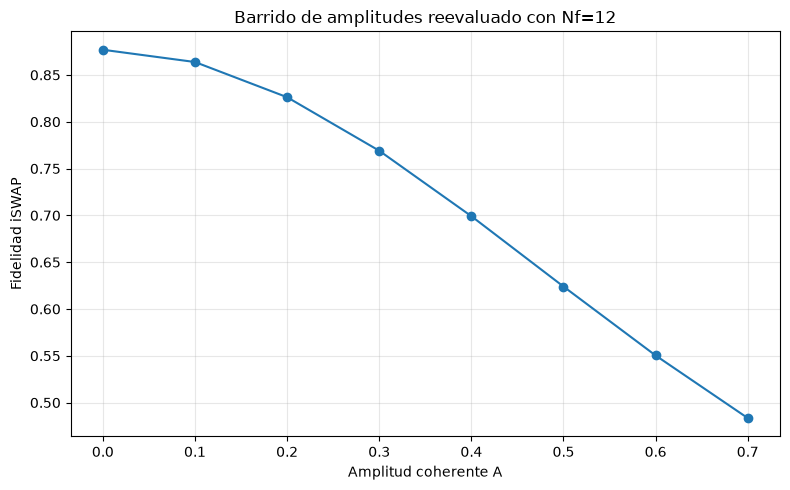


Reevaluación terminada.


In [68]:
# Unificación del barrido de amplitudes con Nf=12.
# Esta celda REEVALÚA parámetros existentes; no los reoptimiza.

import numpy as np
import matplotlib.pyplot as plt

phi_unified = 1.5916841115
g_unified = 1.0
Nf_unified = 12

# Formato:
# (A, J/g de la rama corta, tg de la rama corta,
#     J/g de la rama de mayor tiempo, tg de la rama de mayor tiempo)

previous_candidates = [
    (0.0, 0.504637, 5.691754, 1.513686, 9.646166),
    (0.1, 0.504436, 5.691338, 1.513878, 9.646115),
    (0.2, 0.504003, 5.690255, 1.514445, 9.646434),
    (0.3, 0.503830, 5.689054, 1.515363, 9.648577),
    (0.4, 0.504748, 5.688731, 1.516609, 9.654785),
    (0.5, 0.507711, 5.690734, 1.518211, 9.667928),
    (0.6, 0.513262, 5.696397, 1.520351, 9.690210),
    (0.7, 0.520900, 5.705548, 1.523844, 9.720540)
]

unified_results_all = []
unified_results_best = []

print("=" * 100)
print("REEVALUACIÓN DE LAS AMPLITUDES A = 0.0,...,0.7 CON Nf=12")
print("=" * 100, flush=True)

for A, J_short, tg_short, J_long, tg_long in previous_candidates:

    candidates_A = []

    branches = [
        ("Rama corta", J_short, tg_short),
        ("Rama de mayor tiempo", J_long, tg_long)
    ]

    print(f"\nA = {A:.1f}; ocupación media total = {2*A**2:.4f}",
          flush=True)

    for branch, J_over_g, tg in branches:

        result = evaluate_point(
            J=J_over_g * g_unified,
            t=tg / g_unified,
            alpha=A,
            beta=A * np.exp(1j * phi_unified),
            g=g_unified,
            Nf=Nf_unified
        )

        row = {
            "A": float(A),
            "mean_photons": float(2*A**2),
            "branch": branch,
            "J_over_g": float(J_over_g),
            "tg": float(tg),
            "F": float(result["F_iSWAP"]),
            "P": float(result["avg_purity"]),
            "S": float(result["avg_entropy"])
        }

        unified_results_all.append(row)
        candidates_A.append(row)

        print(
            f"  {branch}: "
            f"F={row['F']:.10f}, "
            f"P={row['P']:.10f}, "
            f"S={row['S']:.10f} bits",
            flush=True
        )

    best_A = max(candidates_A, key=lambda r: r["F"])
    unified_results_best.append(best_A)

    print(
        f"  Mejor candidato reevaluado: "
        f"F={best_A['F']:.10f}; "
        f"J/g={best_A['J_over_g']:.6f}; "
        f"tg={best_A['tg']:.6f}",
        flush=True
    )


# Tabla resumen, sin pandas
print("\n" + "=" * 100)
print("MEJORES CANDIDATOS REEVALUADOS CON Nf=12")
print("=" * 100)

print(
    f"{'A':>5} {'<n_total>':>12} {'Rama':>25} "
    f"{'J/g':>11} {'tg':>11} {'Fidelidad':>14} "
    f"{'Pureza':>12} {'Entropía':>12}"
)

for r in unified_results_best:
    print(
        f"{r['A']:5.2f} "
        f"{r['mean_photons']:12.4f} "
        f"{r['branch']:>25} "
        f"{r['J_over_g']:11.6f} "
        f"{r['tg']:11.6f} "
        f"{r['F']:14.8f} "
        f"{r['P']:12.8f} "
        f"{r['S']:12.8f}"
    )


# Gráfica de fidelidad reevaluada
plt.figure(figsize=(8, 5))
plt.plot(
    [r["A"] for r in unified_results_best],
    [r["F"] for r in unified_results_best],
    marker="o"
)
plt.xlabel("Amplitud coherente A")
plt.ylabel("Fidelidad iSWAP")
plt.title("Barrido de amplitudes reevaluado con Nf=12")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


print("\nReevaluación terminada.", flush=True)

## Reevaluación del barrido de amplitudes con Nf = 12

Para unificar la dimensión de truncamiento en el estudio de las amplitudes coherentes, se reevaluaron con $N_f=12$ los parámetros encontrados previamente para $A=0,0.1,\ldots,0.7$. En cada amplitud se compararon dos candidatos: uno correspondiente a la región de tiempos más cortos y otro a la región de mayor tiempo de evolución.

La preparación inicial del campo se mantuvo en la forma

$$
\alpha=A,\qquad \beta=Ae^{i\varphi},
$$

con fase relativa fija

$$
\varphi=1.5916841115\ \text{rad}.
$$

La ocupación media total está dada por

$$
\langle n_++n_-\rangle=2A^2.
$$

### Dependencia de la fidelidad con la amplitud

En las ocho amplitudes analizadas, el candidato de la región de mayor tiempo proporcionó la mayor fidelidad de las dos soluciones reevaluadas. La fidelidad disminuyó de $0.87691852$ para $A=0$ a $0.48346090$ para $A=0.7$.

Esta tendencia indica que, para la fase relativa y los parámetros dinámicos considerados, aumentar la ocupación media inicial del campo se asocia con una reducción de la fidelidad iSWAP encontrada por el procedimiento de optimización anterior.

La pureza promedio disminuyó de $0.78852876$ a $0.47684079$, mientras que la entropía promedio aumentó de $0.56331062$ a $1.37665394$ bits. Estas variaciones son consistentes con una mayor mezcla de los estados reducidos de los qubits en las entradas consideradas.

### Alcance de la comparación

Esta etapa consiste en una reevaluación con una dimensión de Fock común, no en una nueva optimización completa con $N_f=12$. Por tanto, permite comparar las métricas usando la misma dimensión de la base, pero no garantiza que los parámetros seleccionados continúen siendo óptimos después de aumentar el truncamiento.

Los resultados se interpretan como los mejores candidatos entre las dos ramas comparadas para cada amplitud. No constituyen una demostración de optimalidad global.

In [69]:
# Comprobación directa del candidato anterior para A = 0.9.
# No ejecuta ninguna optimización.

A_check = 0.9
phi_check = 1.5916841115

candidate_A09 = evaluate_point(
    J=0.53737488,
    t=5.72357536,
    alpha=A_check,
    beta=A_check * np.exp(1j * phi_check),
    g=1.0,
    Nf=12
)

print("COMPROBACIÓN DIRECTA PARA A = 0.9, Nf = 12")
print(f"Fidelidad: {candidate_A09['F_iSWAP']:.10f}")
print(f"Pureza promedio: {candidate_A09['avg_purity']:.10f}")
print(f"Entropía promedio: {candidate_A09['avg_entropy']:.10f} bits")

COMPROBACIÓN DIRECTA PARA A = 0.9, Nf = 12
Fidelidad: 0.3839731397
Pureza promedio: 0.4409119560
Entropía promedio: 1.4624218725 bits


## Resultados consolidados de la fidelidad iSWAP en función de la amplitud coherente

Se consolidaron los resultados del barrido de amplitudes coherentes, evaluando las métricas con una dimensión de truncamiento común de \(N_f=12\). Se consideraron estados iniciales de los modos normales de la forma

\[
\alpha=A,\qquad \beta=Ae^{i\varphi},
\]

con fase relativa fija \(\varphi=1.5916841115\) rad. La ocupación media total del campo está dada por

\[
\langle n_++n_-\rangle=2A^2.
\]

Para cada amplitud se conservaron los mejores candidatos identificados mediante las búsquedas numéricas previas, después de comparar diferentes regiones de convergencia.

### 1. Tendencia de la fidelidad con la amplitud

La mayor fidelidad encontrada para el campo vacío fue \(0.87691852\). Al aumentar la amplitud a \(A=0.5\), la fidelidad encontrada descendió a \(0.62396256\). Para \(A=1.0\), el mejor candidato identificado presentó una fidelidad de \(0.33474044\).

En general, la fidelidad disminuye al incrementar la amplitud coherente en los puntos examinados. Esta tendencia indica que el ajuste de los parámetros dinámicos no compensa por completo los cambios en la preparación inicial del campo para la fase relativa estudiada.

Sin embargo, los resultados deben interpretarse como los mejores candidatos encontrados mediante el procedimiento de búsqueda utilizado. No demuestran que la fidelidad máxima global del sistema tenga que disminuir monótonamente para cualquier amplitud o fase.

### 2. Comportamiento de la pureza y la entropía

La pureza promedio disminuye de \(0.78852876\) para el vacío a \(0.39969315\) para \(A=1.0\). Por su parte, la entropía promedio aumenta de \(0.56331062\) a \(1.59834291\) bits.

Estas tendencias son consistentes con estados reducidos de los qubits más mezclados para las entradas computacionales evaluadas. Dado que el sistema completo evoluciona unitariamente desde estados iniciales puros, la entropía del subsistema de qubits cuantifica su entrelazamiento con el campo para cada entrada particular. La magnitud reportada en la tabla es el promedio sobre las cuatro entradas de la base computacional.

La fidelidad, la pureza y la entropía describen propiedades diferentes. Por ello, deben analizarse conjuntamente y no utilizarse como medidas intercambiables.

### 3. Variación de los parámetros encontrados

Aunque las métricas presentan una tendencia general clara, los parámetros \(J/g\) y \(tg\) no cambian de forma uniforme en todas las amplitudes. Esto se debe, en parte, a que las búsquedas identificaron diferentes regiones de convergencia: por ejemplo, para \(A=0.85\) y \(A=0.90\), los mejores candidatos encontrados pertenecen a la región de menor tiempo, mientras que en otras amplitudes se seleccionaron soluciones de regiones distintas.

Este comportamiento pone de manifiesto la importancia de comparar diversos puntos iniciales y documentar el procedimiento de optimización.

### 4. Alcance de los resultados

La tabla utiliza una dimensión de truncamiento común para evaluar las métricas, pero no todos los parámetros se optimizaron originalmente con \(N_f=12\). Por tanto, los resultados constituyen una comparación consolidada de candidatos reevaluados, no una demostración de optimalidad global ni una optimización uniforme de todas las amplitudes con la misma dimensión.

Para establecer conclusiones definitivas sobre los parámetros óptimos, sería necesario reoptimizar los puntos que se quieran destacar con \(N_f=12\), comparar las soluciones obtenidas desde varios puntos iniciales y verificar la estabilidad de las métricas.

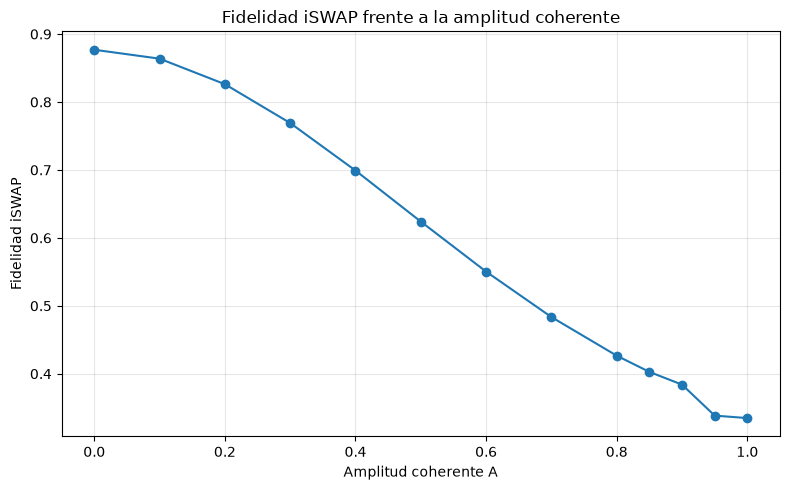

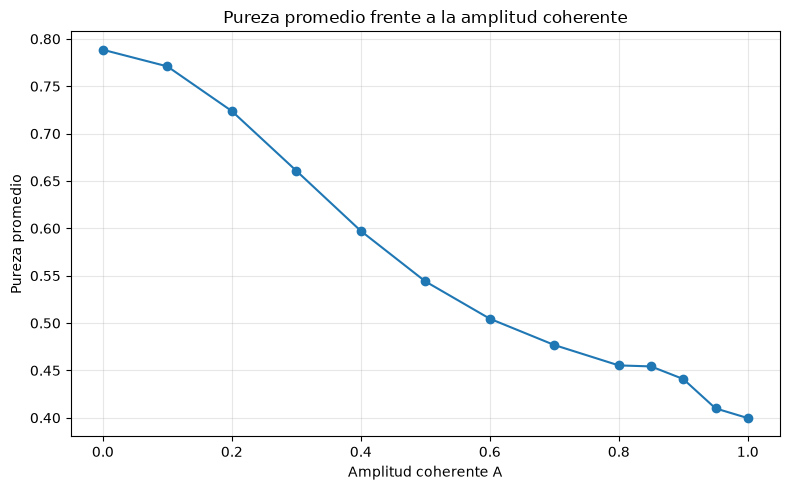

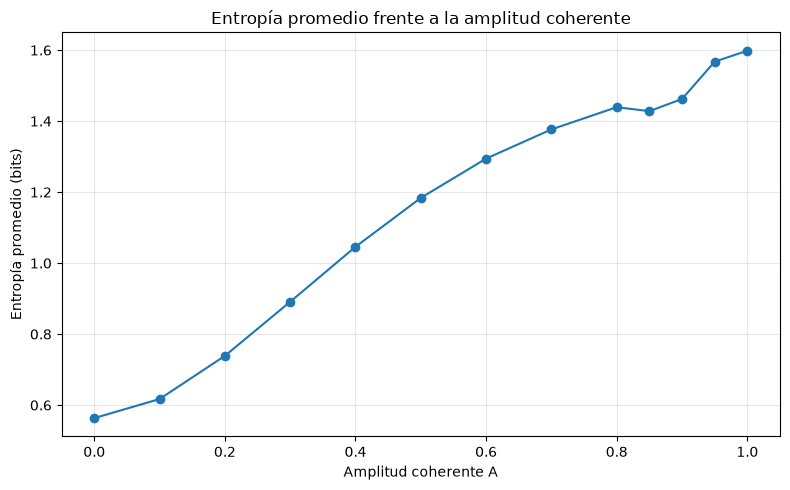

In [70]:
import numpy as np
import matplotlib.pyplot as plt

# Tabla consolidada, evaluada con Nf=12.
A_values = np.array([
    0.00, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60,
    0.70, 0.80, 0.85, 0.90, 0.95, 1.00
])

F_values = np.array([
    0.8769185190, 0.8638025800, 0.8262178233,
    0.7690339478, 0.6991242176, 0.6239625593,
    0.5503380364, 0.4834608998, 0.4265872543,
    0.4027185738, 0.3839731397, 0.3383687572,
    0.3347404411
])

P_values = np.array([
    0.7885287590, 0.7709593938, 0.7237835198,
    0.6607701474, 0.5972701295, 0.5440063638,
    0.5045953277, 0.4768407914, 0.45530870,
    0.45422902, 0.4409119560, 0.40993578,
    0.3996931245
])

S_values = np.array([
    0.5633106211, 0.6171430010, 0.7387134407,
    0.8911242905, 1.0459122027, 1.1837124411,
    1.2943745796, 1.3766539384, 1.43927835,
    1.42796231, 1.4624218725, 1.56746775,
    1.59834291
])

# Figura 1: fidelidad
plt.figure(figsize=(8, 5))
plt.plot(A_values, F_values, marker="o")
plt.xlabel("Amplitud coherente A")
plt.ylabel("Fidelidad iSWAP")
plt.title("Fidelidad iSWAP frente a la amplitud coherente")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figura 2: pureza promedio
plt.figure(figsize=(8, 5))
plt.plot(A_values, P_values, marker="o")
plt.xlabel("Amplitud coherente A")
plt.ylabel("Pureza promedio")
plt.title("Pureza promedio frente a la amplitud coherente")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figura 3: entropía promedio
plt.figure(figsize=(8, 5))
plt.plot(A_values, S_values, marker="o")
plt.xlabel("Amplitud coherente A")
plt.ylabel("Entropía promedio (bits)")
plt.title("Entropía promedio frente a la amplitud coherente")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [71]:
# ÚLTIMA COMPROBACIÓN:
# Reoptimización directa con Nf=12 para A = 0, 0.5 y 0.7.
# Se comparan las dos regiones de convergencia identificadas.

import numpy as np
from scipy.optimize import minimize

phi_test = 1.5916841115
Nf_test = 12

# A, J/g inicial corto, tg inicial corto,
#    J/g inicial largo, tg inicial largo
test_cases = [
    (0.0, 0.504637, 5.691754, 1.513686, 9.646166),
    (0.5, 0.507711, 5.690734, 1.518211, 9.667928),
    (0.7, 0.520900, 5.705548, 1.523844, 9.720540)
]

bounds_test = [
    (0.05, 2.0),   # J/g
    (0.1, 12.0)    # t*g
]


def objective_uniform_Nf(x, A):
    J_over_g, tg = x

    result = evaluate_point(
        J=J_over_g,
        t=tg,
        alpha=A,
        beta=A * np.exp(1j * phi_test),
        g=1.0,
        Nf=Nf_test
    )

    return -float(result["F_iSWAP"])


final_check_results = []

for A, J_short, tg_short, J_long, tg_long in test_cases:

    print("\n" + "=" * 75, flush=True)
    print(f"OPTIMIZACIÓN CON Nf=12 PARA A={A:.1f}", flush=True)
    print("=" * 75, flush=True)

    starts = [
        ("Rama corta", [J_short, tg_short]),
        ("Rama de mayor tiempo", [J_long, tg_long])
    ]

    candidates = []

    for branch, x0 in starts:

        print(f"\nEjecutando {branch}...", flush=True)

        opt = minimize(
            objective_uniform_Nf,
            x0=np.array(x0, dtype=float),
            args=(A,),
            method="Powell",
            bounds=bounds_test,
            options={
                "maxiter": 80,
                "xtol": 1e-4,
                "ftol": 1e-7,
                "disp": False
            }
        )

        J_opt = float(opt.x[0])
        tg_opt = float(opt.x[1])

        metrics = evaluate_point(
            J=J_opt,
            t=tg_opt,
            alpha=A,
            beta=A * np.exp(1j * phi_test),
            g=1.0,
            Nf=Nf_test
        )

        row = {
            "A": float(A),
            "branch": branch,
            "J_over_g": J_opt,
            "tg": tg_opt,
            "F": float(metrics["F_iSWAP"]),
            "P": float(metrics["avg_purity"]),
            "S": float(metrics["avg_entropy"]),
            "success": bool(opt.success),
            "nfev": int(opt.nfev)
        }

        final_check_results.append(row)
        candidates.append(row)

        print(f"  J/g:          {J_opt:.8f}")
        print(f"  tg:           {tg_opt:.8f}")
        print(f"  Fidelidad:    {row['F']:.10f}")
        print(f"  Pureza:       {row['P']:.10f}")
        print(f"  Entropía:     {row['S']:.10f} bits")
        print(f"  Convergencia: {row['success']}")
        print(f"  Evaluaciones: {row['nfev']}", flush=True)

    converged = [r for r in candidates if r["success"]]
    pool = converged if converged else candidates
    best = max(pool, key=lambda r: r["F"])

    print("\nMEJOR CANDIDATO ENCONTRADO", flush=True)
    print(f"  A = {A:.2f}")
    print(f"  Rama = {best['branch']}")
    print(f"  J/g = {best['J_over_g']:.8f}")
    print(f"  tg = {best['tg']:.8f}")
    print(f"  Fidelidad = {best['F']:.10f}", flush=True)


# Tabla final de los mejores candidatos
print("\n" + "=" * 95)
print("RESUMEN FINAL DE LA REOPTIMIZACIÓN CON Nf=12")
print("=" * 95)

print(
    f"{'A':>5} {'Rama':>25} {'J/g':>12} {'tg':>12} "
    f"{'Fidelidad':>14} {'Pureza':>12} {'Entropía':>12}"
)

for A, *_ in test_cases:

    candidates_A = [
        r for r in final_check_results
        if np.isclose(r["A"], A)
    ]

    converged_A = [r for r in candidates_A if r["success"]]
    pool_A = converged_A if converged_A else candidates_A
    best = max(pool_A, key=lambda r: r["F"])

    print(
        f"{best['A']:5.2f} "
        f"{best['branch']:>25} "
        f"{best['J_over_g']:12.6f} "
        f"{best['tg']:12.6f} "
        f"{best['F']:14.8f} "
        f"{best['P']:12.8f} "
        f"{best['S']:12.8f}"
    )

print("\nComprobación final terminada.", flush=True)


OPTIMIZACIÓN CON Nf=12 PARA A=0.0

Ejecutando Rama corta...
  J/g:          0.50463603
  tg:           5.69175445
  Fidelidad:    0.8636332790
  Pureza:       0.7371595577
  Entropía:     0.6706436988 bits
  Convergencia: True
  Evaluaciones: 22

Ejecutando Rama de mayor tiempo...
  J/g:          1.51368416
  tg:           9.64617129
  Fidelidad:    0.8769185190
  Pureza:       0.7885304961
  Entropía:     0.5633068091 bits
  Convergencia: True
  Evaluaciones: 22

MEJOR CANDIDATO ENCONTRADO
  A = 0.00
  Rama = Rama de mayor tiempo
  J/g = 1.51368416
  tg = 9.64617129
  Fidelidad = 0.8769185190

OPTIMIZACIÓN CON Nf=12 PARA A=0.5

Ejecutando Rama corta...
  J/g:          0.50770957
  tg:           5.69073427
  Fidelidad:    0.6130197060
  Pureza:       0.5875790437
  Entropía:     1.0734870693 bits
  Convergencia: True
  Evaluaciones: 21

Ejecutando Rama de mayor tiempo...
  J/g:          1.51820610
  tg:           9.66794286
  Fidelidad:    0.6239625593
  Pureza:       0.5440072429
  E

## Cierre de la validación numérica del barrido de amplitudes

Como comprobación final, se realizó una optimización directa con $N_f=12$ para las amplitudes $A=0$, $A=0.5$ y $A=0.7$, considerando dos puntos iniciales asociados a las regiones de convergencia previamente identificadas.

Para las tres amplitudes, la solución de mayor tiempo proporcionó la mayor fidelidad entre las dos ramas examinadas. Los parámetros encontrados fueron aproximadamente

$$
\frac{J}{g}=1.513684,\qquad tg=9.646171
$$

para $A=0$,

$$
\frac{J}{g}=1.518206,\qquad tg=9.667943
$$

para $A=0.5$, y

$$
\frac{J}{g}=1.523858,\qquad tg=9.720499
$$

para $A=0.7$.

Las fidelidades correspondientes fueron $0.87691852$, $0.62396256$ y $0.48346090$, respectivamente. Estos resultados son consistentes con la tendencia general observada en el barrido: para la fase relativa estudiada, la fidelidad encontrada disminuye al incrementar la amplitud coherente.

La comparación con las evaluaciones anteriores también muestra que, para estos puntos, las métricas permanecen estables al realizar la optimización directamente con $N_f=12$.

Con esta comprobación se da por cerrada la validación prevista para las tres amplitudes representativas. Los resultados se utilizarán para consolidar las tablas y figuras del análisis numérico. Las conclusiones se limitarán a las soluciones encontradas mediante el procedimiento de optimización utilizado, sin afirmar que se ha demostrado la optimalidad global.

In [72]:
A_values = np.array([
    0.00, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60,
    0.70, 0.80, 0.85, 0.90, 0.95, 1.00
])

F_values = np.array([
    0.8769185190, 0.8638025800, 0.8262178233,
    0.7690339478, 0.6991242176, 0.6239625593,
    0.5503380364, 0.4834608995, 0.4265872543,
    0.4027185738, 0.3839731397, 0.3383687572,
    0.3347404411
])

P_values = np.array([
    0.7885304961, 0.7709593938, 0.7237835198,
    0.6607701474, 0.5972701295, 0.5440072429,
    0.5045953277, 0.4768409765, 0.45530870,
    0.45422902, 0.4409119560, 0.40993578,
    0.3996931245
])

S_values = np.array([
    0.5633068091, 0.6171430010, 0.7387134407,
    0.8911242905, 1.0459122027, 1.1837102042,
    1.2943745796, 1.3766530998, 1.43927835,
    1.42796231, 1.4624218725, 1.56746775,
    1.5983433818
])